## Task Group 0: Notebook Setup & Reproducible Data Loading

### Question

Can this notebook independently and reproducibly load the FD001 data, construct the training RUL target, and establish the inputs needed for the baseline pipeline without depending on state created in the EDA notebook?

### Why this matters

A notebook should not depend on variables that happened to exist because another notebook was previously executed.

The EDA notebook established conclusions about the dataset, but the baseline pipeline should reproduce its required data objects from reusable source code.

This gives us a clean dependency chain:

raw FD001 files
→ reusable loading code
→ reusable target-construction code
→ modeling-ready notebook state

Reproducibility means that after restarting the kernel and running this notebook from top to bottom, the same inputs should be reconstructed without manually copying intermediate variables from `01_eda.ipynb`.

In [1]:
# --- Import the core libraries needed by the baseline-pipeline notebook ---
#
# What this does:
# - `sys` lets us inspect which Python interpreter is executing the notebook.
# - `numpy` and `pandas` provide the numerical/dataframe tools used throughout
#   the pipeline.
#
# Why this matters:
# A reproducible notebook begins by explicitly declaring its dependencies
# instead of relying on imports left over from previous notebook execution.
#
# Concept to focus on:
# Restarting the kernel should remove all notebook state. If this notebook
# still runs from top to bottom afterward, its dependencies are explicit.

import sys

import numpy as np
import pandas as pd

I expect this notebook to be using Python version 13.1. I ran "python --version" in the .venv that I'm making this project in.

In [2]:
# --- Verify which Python interpreter is running this notebook ---
#
# What this does:
# Prints the exact Python executable being used by the Jupyter kernel.
#
# Why this matters:
# A notebook can appear to be inside the correct repository while actually
# running a completely different Python environment. That can create confusing
# dependency/version problems.
#
# Concept to focus on:
# The working directory and the Python environment are separate things.
# Being inside the repository does NOT automatically mean Jupyter is using
# the repository's virtual environment.

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
/Users/stuart/repos/ml-predictive-maintenance-mlops/.venv/bin/python3

Python version:
3.13.1 (main, Dec  3 2024, 17:59:52) [Clang 16.0.0 (clang-1600.0.26.4)]


In [3]:
# --- Import project configuration and reusable C-MAPSS data utilities ---
#
# What this does:
# - Imports the dataset name and fixed random seed from project configuration.
# - Imports the canonical C-MAPSS column definitions.
# - Imports the reusable raw-data loader.
# - Imports the reusable training-RUL construction function.
#
# Why this matters:
# Business/data logic should increasingly live in reusable source modules,
# while notebooks orchestrate, inspect, and explain that logic.
#
# Concept to focus on:
# We do NOT want separate implementations of RUL construction in every
# notebook. One tested implementation should be reused everywhere.

from predictive_maintenance.config import DATASET_NAME, RANDOM_STATE

from predictive_maintenance.data.cmapss import (
    CMAPSS_COLUMNS,
    ID_COLUMNS,
    OPERATING_SETTING_COLUMNS,
    SENSOR_COLUMNS,
    load_cmapss_subset,
)

from predictive_maintenance.data.targets import add_training_rul

In [4]:
# --- Display the core project configuration used by this notebook ---
#
# What this does:
# Makes the selected C-MAPSS subset and random seed visible in the notebook.
#
# Why this matters:
# Important experiment configuration should not be hidden several modules
# away when reading the notebook.
#
# Concept to focus on:
# RANDOM_STATE will become important once we start making reproducible
# train/validation splits.

print(f"Dataset: {DATASET_NAME}")
print(f"Random state: {RANDOM_STATE}")

Dataset: FD001
Random state: 42


training rows:      ~20,000

test rows:          ~13,000

training columns:   26

test RUL labels:    100

In [5]:
# --- Load the raw FD001 training, test, and endpoint-RUL files ---
#
# What this does:
# Loads all three FD001 components through the reusable project loader:
# - complete run-to-failure training trajectories,
# - truncated test trajectories,
# - one endpoint RUL label for each test engine.
#
# Why this matters:
# This notebook must reconstruct its inputs directly from the canonical raw
# files rather than reading variables or processed dataframes from `01_eda`.
#
# Concept to focus on:
# Training and test have the same measurement schema, but their trajectory
# semantics differ: training runs to failure; test histories are truncated.

train_df, test_df, test_rul_df = load_cmapss_subset(
    DATASET_NAME
)

In [6]:
# --- Confirm the shapes of all three loaded FD001 components ---
#
# What this does:
# Provides a fast sanity check that the expected dataset was loaded.
#
# Why this matters:
# Unexpected dimensions can indicate the wrong dataset, parsing problems,
# altered raw files, or an incorrect data path.
#
# Concept to focus on:
# Shape checks are cheap invariants. They do not prove the dataset is correct,
# but they can detect many loading failures immediately.

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Test RUL shape:", test_rul_df.shape)

Training shape: (20631, 26)
Test shape: (13096, 26)
Test RUL shape: (100, 1)


In [7]:
# --- Verify that train and test use the canonical C-MAPSS feature schema ---
#
# What this does:
# Checks that both raw dataframes contain exactly the expected 26 columns
# and that they appear in the canonical order.
#
# Why this matters:
# Later feature-selection code assumes specific semantic groups:
# identifiers, operating settings, and sensor measurements.
#
# Concept to focus on:
# Feature pipelines should depend on named schema contracts rather than on
# fragile assumptions such as "column 7 is probably Sensor 2."

assert train_df.columns.tolist() == CMAPSS_COLUMNS
assert test_df.columns.tolist() == CMAPSS_COLUMNS

print("Train/test schema matches the canonical C-MAPSS schema.")

print("\nColumn groups:")
print(f"Identifier/sequence columns: {len(ID_COLUMNS)}")
print(f"Operating-setting columns:   {len(OPERATING_SETTING_COLUMNS)}")
print(f"Sensor columns:              {len(SENSOR_COLUMNS)}")
print(f"Total columns:               {len(CMAPSS_COLUMNS)}")

Train/test schema matches the canonical C-MAPSS schema.

Column groups:
Identifier/sequence columns: 2
Operating-setting columns:   3
Sensor columns:              21
Total columns:               26


In [8]:
# --- Construct the supervised training RUL target from complete trajectories ---
#
# What this does:
# For each engine:
#   final_cycle = maximum observed cycle
#   rul = final_cycle - current cycle
#
# Why this matters:
# The raw C-MAPSS training file does not contain a row-level RUL target.
# Complete run-to-failure trajectories let us construct that target
# retrospectively.
#
# Concept to focus on:
# `final_cycle` is legal for LABEL CONSTRUCTION because training failures are
# already known retrospectively. It is NOT legal as a predictive input because
# an operating engine's eventual failure cycle is unknown at inference time.

train_labeled_df = add_training_rul(
    train_df
)

In [9]:
# --- Inspect the target columns added by training-RUL construction ---
#
# What this does:
# Shows a small sample of engine identity, current cycle, failure endpoint,
# and constructed RUL.
#
# Why this matters:
# Seeing the relationship directly helps reinforce:
#
#     RUL = final_cycle - cycles
#
# Concept to focus on:
# `rul` is our supervised answer.
# `final_cycle` is retrospective metadata used to construct that answer.
# Neither belongs automatically in the predictive feature matrix.

train_labeled_df[
    [
        "unit_no",
        "cycles",
        "final_cycle",
        "rul",
    ]
].head(10)

,unit_no,cycles,final_cycle,rul
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


In [10]:
# --- Verify the most important invariants of the reconstructed RUL target ---
#
# What this does:
# Confirms that:
# 1. RUL is never negative.
# 2. Every engine's final observed training row has RUL = 0.
#
# Why this matters:
# The modeling pipeline should fail early if a foundational target assumption
# is violated rather than silently fitting a model to corrupted labels.
#
# Concept to focus on:
# EDA discovers and investigates assumptions.
# Pipeline assertions ENFORCE assumptions that we now depend on.

assert (train_labeled_df["rul"] >= 0).all()

final_rows = (
    train_labeled_df
    .sort_values(["unit_no", "cycles"])
    .groupby("unit_no")
    .tail(1)
)

assert (final_rows["rul"] == 0).all()

print("Training RUL sanity checks passed.")

Training RUL sanity checks passed.


In [11]:
# --- Confirm the number of independent engine trajectories in train and test ---
#
# What this does:
# Counts unique engine identifiers in each dataset and compares the test-engine
# count with the number of official endpoint RUL labels.
#
# Why this matters:
# Later validation must operate at the ENGINE level, and final test evaluation
# eventually requires exactly one endpoint prediction per test engine.
#
# Concept to focus on:
# Rows are observations, but engines are the independent sequence/group units.

n_train_engines = train_df["unit_no"].nunique()
n_test_engines = test_df["unit_no"].nunique()
n_test_labels = len(test_rul_df)

print(f"Training engines: {n_train_engines}")
print(f"Test engines:     {n_test_engines}")
print(f"Test RUL labels:  {n_test_labels}")

assert n_test_engines == n_test_labels

Training engines: 100
Test engines:     100
Test RUL labels:  100


In [12]:
# --- Verify that official test RUL answers remain separate from test features ---
#
# What this does:
# Confirms that the endpoint RUL labels have not been merged into the test
# feature dataframe.
#
# Why this matters:
# The official RUL labels are final-evaluation answers. They must not influence
# feature engineering, preprocessing, model selection, or hyperparameters.
#
# Concept to focus on:
# `test_df` will eventually provide model inputs.
# `test_rul_df` provides the answer sheet used only after development choices
# have been finalized.

assert "endpoint_rul" not in test_df.columns

print("Official test endpoint labels remain separate from test features.")

Official test endpoint labels remain separate from test features.


### Data roles entering Phase 1.3

The baseline pipeline will eventually separate the training data into three conceptually different objects:

**X — predictive inputs**

Information the model is allowed to use when estimating RUL.

**y — supervised target**

The true RUL values the model learns to predict.

**groups — engine identity**

`unit_no` will control grouped train/validation splitting and temporal boundaries but will not itself be treated as a numerical predictive feature.

Keeping these roles separate helps prevent identifiers, targets, and analysis metadata from accidentally entering the feature matrix.

In [13]:
# --- Confirm that Task Group 0 produced the core objects required downstream ---
#
# What this does:
# Performs lightweight checks before feature selection begins.
#
# Why this matters:
# Task Group 1 should start from known-good data objects rather than repeatedly
# wondering whether something went wrong during loading or target creation.
#
# Concept to focus on:
# Pipelines become easier to reason about when each stage establishes a clear
# contract for the next stage.

assert len(train_df) == len(train_labeled_df)
assert train_df.shape[1] == len(CMAPSS_COLUMNS)
assert test_df.shape[1] == len(CMAPSS_COLUMNS)
assert train_labeled_df["unit_no"].nunique() == 100
assert test_df["unit_no"].nunique() == 100

print("Task Group 0 readiness checks passed.")

Task Group 0 readiness checks passed.


### Task Group 0 — Interpretation Questions

1. **Why shouldn't `02_baseline_pipeline.ipynb` simply depend on `train_labeled_df` having already been created in `01_eda.ipynb`?**

Because each notebook should be able to independently create modified datasets. We need to be able to reproduce results in a vacuum when it comes to distinct notebooks rather than depending on the work of previous notebooks. From a scientific standpoint, experiments need to be repeatable.

2. **What are the three FD001 files/objects we load, and what role does each serve?**

There's a training file, which contains data for all the training engines—the data rows here run until failure. There's a test file, which contains data for all the test engines—the data rows here are truncated and end before the final cycle. There's a targets file, which contains the target or ground truth label for each of the test engines to check model accuracy.

3. **Why can we construct a row-level RUL target for every training observation but not for every test observation?**

Because the test engines are truncated. There is a section of the engine's lifecycle omitted from the data, which means we don't know what the RUL could be until it's time for calling on the target file and checking model accuracy.

4. **What exactly does `add_training_rul()` need to know in order to construct RUL?**

It need to know the final cycle of each engine. From there you simply take the difference of the final cycle and the current cycle to calculate RUL for each data row. 

5. **Why is `final_cycle` legitimate inside target construction but illegitimate inside the eventual predictive feature matrix?**

To build the model we need to have a target for each engine. This is done by construction using the existing data. But when it's time to make predictions using the model, we cannot have access to that information. If it leaked into the predictive feature matrix, then the parameters associated with those leakage datapoints would get tuned up while all the other parameters would get tuned down. Then the model wouldn't be able to generalize on unforseen data where we don't have access to RUL.

**Future outcomes may be used retrospectively to construct training labels. They cannot be predictive inputs because they won't exist at inference time.**

6. **Why are assertions such as “every training engine ends at RUL 0” still useful here even though we already validated them during EDA?**

Because data modifications and checks need to be reproducible between different notebooks. If we're going to make data augmentations within this notebook, then we should still carry out quality checks. Otherwise we would risk making a mistake in this notebook that wasn't made in the other notebook. A situation like that could greatly impact model accuracy.

7. **What is the conceptual difference between EDA checking an assumption and a production/data pipeline asserting an assumption?**

In EDA we investigate the data and figure out different facts. In a production/data pipeline assertion we assume the facts from the EDA to be true and simply check if they're still true rather than devoting resources to a second investigation. If the assertions are true, then we've confirmed there's no need for a second investigation.

**Reproduce the required state. Don't reproduce the exploration that originally justified it.**

8. **Why do we care that there are 100 test engines and exactly 100 endpoint RUL labels?**

Because a mismatch would indicate missing or corrupted data. If we do not have a ground truth label for an engine in the test set, then that engine would likely need to be excluded from analysis.

9. **Why are we deliberately keeping `test_rul_df` separate from `test_df` during development?**

Because `test_rul_df` has data that is reserved strictly for checking the accuracy of a finalized model. Letting ourselves include that in our model development would be analagous to peeking at an answer sheet while taking a test. Including it in model development would run the risk of invalidating predictive capabilities and ruining the model's ability to generalize to never before seen data. 

**Validation chooses the model. Test evaluates the chosen model.**

10. **Explain the conceptual difference among `X`, `y`, and `groups`. Where will `unit_no` eventually belong?**

`X` is the input feature matrix. This contains all the rows needed to train a model, strictly containing 3 sensor readings and 23 sensor measurements. The `unit_no` get excluded from this. `y` is the training target in the form of RUL. This is the data column that we are tuning the parameters of our model to predict as accurately as possible. `groups` is the tool for setting boundaries between different engines in the data, and this is where `unit_no` belongs to facilitate that. 

**X = predictive features**

**y = rul**

**groups = unit_no**

11. **Why is checking the active Python interpreter relevant to reproducibility? Isn't being inside the correct repository enough?**

Different versions of Python could have different interactions with the code we are using. Experiments and software actions need to be reproducible, and changing the Python interpreter could ruin that. Also, just because you're in the correct repository doesn't mean all the necessary packages have been activate, as in the case of this project functioning in a virtual environment that needs be activated for code to function. For example, there are package imports that may be only be configured for use in the virtual environment. 

**The notebook kernel must point at the intended project environment.**

12. **Suppose you restarted the kernel and this notebook failed because `baseline_measurement_features` no longer existed. What would that tell you about the notebook's design?**

That would tell you a design flaw is on your hands and you may have made a mistake of using results that got loaded by a different notebook. Notebooks for a project like this should be able to work in a vacuum, as data loading should be reproducible and offer another layer of confirmation that any other notebooks succeeded in doing. 

13. **What should Task Group 0 reproduce from source code, and what should it *not* redo from the EDA notebook?**

It should be able to reproduce confirmations that were made in the EDA notebook. But it should not redo the entire analysis. The EDA notebook should figure out facts about the data and add critical pieces of information that should be easily reproduced inside all proceeding notebooks.

14. **Anything in this setup that feels unclear or unnecessarily repetitive?**

I'm feeling reasonably competent for these questions. I'm sure there are some things I got wrong though. 

## Task Group 1: Leakage-Safe Raw Feature Set

### Question

Which raw FD001 variables should be available to the baseline model, which variables must remain outside the predictive feature matrix, and how can those decisions be encoded as a reproducible feature contract?

### Why this matters

A dataframe may contain columns serving very different purposes:

- predictive measurements,
- sequence information,
- identifiers,
- supervised targets,
- retrospective failure information,
- and analysis-only metadata.

Passing the entire dataframe directly into a model would therefore be unsafe.

The pipeline should explicitly define which columns belong in the predictive feature matrix rather than relying on informal rules such as "drop a few columns before training."

The initial raw baseline will use only information that is:

1. available at prediction time,
2. potentially predictive,
3. nonconstant in the training data,
4. and not derived from the target or future failure information.

### From exploration to a feature contract

The EDA notebook discovered that seven of the 24 measurement variables are exactly constant in FD001 training data.

The pipeline notebook should not rediscover those features every time it runs. Instead, the EDA result becomes an explicit project decision:

- remove the seven exactly constant measurements,
- retain the remaining 17 measurements,
- add current cycle number as an observable engine-age feature,
- and keep identifiers, targets, and future information outside the predictive feature matrix.

This is different from learned feature selection.

If a later experiment selects features based on correlation, model importance, PCA, or another data-dependent criterion, that selection must be learned within the training portion of validation.

The seven exact constants are instead being treated as a fixed feature-policy decision established during EDA.

In [14]:
# --- Import the reusable baseline feature contract ---
#
# What this does:
# Loads the feature-policy decisions established during EDA from reusable
# project source code.
#
# Why this matters:
# Later notebooks should share one canonical definition of the baseline
# feature set rather than independently recreating lists of columns.
#
# Concept to focus on:
# The EDA notebook DISCOVERED which features should be excluded.
# This source module now ENCODEs that decision for downstream modeling.

from predictive_maintenance.features.feature_sets import (
    BASELINE_MEASUREMENT_FEATURES,
    BASELINE_RAW_FEATURES,
    CONSTANT_MEASUREMENT_FEATURES,
    EDA_ONLY_COLUMNS,
    FUTURE_INFORMATION_COLUMNS,
    GROUP_COLUMN,
    NON_PREDICTIVE_COLUMNS,
    TARGET_COLUMN,
)

In [15]:
# --- Inspect the size of the baseline feature contract ---
#
# What this does:
# Counts the measurements excluded by EDA, the measurements retained, and the
# complete raw baseline feature set.
#
# Why this matters:
# Feature counts are simple invariants that can expose accidental additions or
# removals from the modeling contract.
#
# Concept to focus on:
# We began with 24 measurement variables:
#   3 operating settings + 21 sensors.
#
# Removing 7 exact constants should leave 17 measurements.
# Adding `cycles` should produce 18 raw baseline predictors.

print(
    "Constant measurement features:",
    len(CONSTANT_MEASUREMENT_FEATURES),
)

print(
    "Retained measurement features:",
    len(BASELINE_MEASUREMENT_FEATURES),
)

print(
    "Raw baseline predictive features:",
    len(BASELINE_RAW_FEATURES),
)

Constant measurement features: 7
Retained measurement features: 17
Raw baseline predictive features: 18


In [16]:
# --- Display the raw predictive feature set explicitly ---
#
# What this does:
# Shows every column that the first baseline model will eventually receive.
#
# Why this matters:
# A modeling feature set should be inspectable and understandable rather than
# being assembled through opaque dataframe slicing.
#
# Concept to focus on:
# `cycles` is the only sequence/age feature.
# The other 17 features are current-cycle measurements.
# There are NO lags, rolling statistics, or slopes yet.

for feature in BASELINE_RAW_FEATURES:
    print(feature)

cycles
op_setting_1
op_setting_2
sensor_measurement_2
sensor_measurement_3
sensor_measurement_4
sensor_measurement_6
sensor_measurement_7
sensor_measurement_8
sensor_measurement_9
sensor_measurement_11
sensor_measurement_12
sensor_measurement_13
sensor_measurement_14
sensor_measurement_15
sensor_measurement_17
sensor_measurement_20
sensor_measurement_21


In [17]:
# --- Verify that retained and constant measurements form a clean partition ---
#
# What this does:
# Confirms that:
# 1. No feature is simultaneously retained and marked constant.
# 2. Together, the retained and constant lists account for every original
#    operating-setting and sensor measurement.
#
# Why this matters:
# Feature-policy bugs can silently occur when a column is accidentally omitted
# from both lists or included in both.
#
# Concept to focus on:
# A clean feature partition means every original measurement has an explicit
# modeling status.

all_measurement_columns = (
    OPERATING_SETTING_COLUMNS
    + SENSOR_COLUMNS
)

retained_set = set(
    BASELINE_MEASUREMENT_FEATURES
)

constant_set = set(
    CONSTANT_MEASUREMENT_FEATURES
)

all_measurement_set = set(
    all_measurement_columns
)

assert retained_set.isdisjoint(
    constant_set
)

assert (
    retained_set
    | constant_set
) == all_measurement_set

print(
    "All 24 measurement features have exactly one "
    "retained/excluded status."
)

All 24 measurement features have exactly one retained/excluded status.


In [18]:
# --- Summarize the different roles played by columns in the pipeline ---
#
# What this does:
# Creates a small human-readable table distinguishing predictive features,
# identifiers, targets, and retrospective future information.
#
# Why this matters:
# Leakage often happens because every numeric column is treated as though it
# were a model feature. Numeric type does NOT imply predictive eligibility.
#
# Concept to focus on:
# Column ROLE determines whether the model may see something, not whether
# pandas describes the column as numeric.

feature_role_summary = pd.DataFrame(
    [
        {
            "role": "Sequence / age predictor",
            "columns": "cycles",
            "allowed_in_X": True,
        },
        {
            "role": "Operating-condition predictors",
            "columns": "op_setting_1, op_setting_2",
            "allowed_in_X": True,
        },
        {
            "role": "Nonconstant sensor predictors",
            "columns": "15 retained sensor measurements",
            "allowed_in_X": True,
        },
        {
            "role": "Engine identifier / grouping metadata",
            "columns": "unit_no",
            "allowed_in_X": False,
        },
        {
            "role": "Supervised target",
            "columns": "rul",
            "allowed_in_X": False,
        },
        {
            "role": "Retrospective future information",
            "columns": "final_cycle",
            "allowed_in_X": False,
        },
        {
            "role": "Exactly constant measurements",
            "columns": "7 EDA-identified constants",
            "allowed_in_X": False,
        },
    ]
)

feature_role_summary

,role,columns,allowed_in_X
0,Sequence / age predictor,cycles,True
1,Operating-condition predictors,"op_setting_1, op_setting_2",True
2,Nonconstant sensor predictors,15 retained sensor measurements,True
3,Engine identifier / grouping metadata,unit_no,False
4,Supervised target,rul,False
5,Retrospective future information,final_cycle,False
6,Exactly constant measurements,7 EDA-identified constants,False


In [19]:
# --- Separate predictive inputs, supervised targets, and engine groups ---
#
# What this does:
# Creates three different modeling objects:
#
# X_baseline:
#     The information the model is allowed to use for prediction.
#
# y_baseline:
#     The RUL values the model is trying to learn.
#
# groups_baseline:
#     Engine identity used to preserve engine boundaries during validation.
#
# Why this matters:
# These three objects serve fundamentally different roles and should not be
# mixed together.
#
# Concept to focus on:
# `unit_no` is NOT useless merely because it is excluded from X.
# It is essential metadata for correct grouped validation.

X_baseline = train_labeled_df[
    BASELINE_RAW_FEATURES
].copy()

y_baseline = train_labeled_df[
    TARGET_COLUMN
].copy()

groups_baseline = train_labeled_df[
    GROUP_COLUMN
].copy()

In [20]:
# --- Construct the matching raw feature matrix for the official test histories ---
#
# What this does:
# Selects exactly the same baseline predictive columns from `test_df`.
#
# Why this matters:
# A trained model expects the same feature schema at inference time that it saw
# during training.
#
# Concept to focus on:
# Feature engineering is a contract between training and inference.
# We cannot train on one set/order of features and predict using another.

X_test_baseline = test_df[
    BASELINE_RAW_FEATURES
].copy()

In [21]:
# --- Verify the dimensions of X, y, groups, and the test feature matrix ---
#
# What this does:
# Confirms that all training objects are row-aligned and that train/test use
# the same number of predictive features.
#
# Why this matters:
# Misaligned targets or groups can produce models that run successfully while
# learning from incorrectly paired observations.
#
# Concept to focus on:
# X, y, and groups describe the SAME training rows but serve different jobs.

print("X_baseline shape:", X_baseline.shape)
print("y_baseline shape:", y_baseline.shape)
print("groups_baseline shape:", groups_baseline.shape)
print("X_test_baseline shape:", X_test_baseline.shape)

X_baseline shape: (20631, 18)
y_baseline shape: (20631,)
groups_baseline shape: (20631,)
X_test_baseline shape: (13096, 18)


In [22]:
# --- Audit the raw baseline feature matrix for forbidden model inputs ---
#
# What this does:
# Verifies that identifiers, targets, retrospective failure information, and
# EDA-only target/future-derived columns are absent from X.
#
# Why this matters:
# Leakage protection should not depend only on remembering which columns to
# drop. The pipeline should detect violations automatically.
#
# Concept to focus on:
# A good feature pipeline is based on an ALLOWLIST:
# explicitly select legal features.
#
# That is safer than taking every dataframe column and trying to remember
# which dangerous columns need to be removed.

forbidden_overlap = (
    set(X_baseline.columns)
    .intersection(NON_PREDICTIVE_COLUMNS)
)

assert not forbidden_overlap, (
    "Forbidden columns found in X: "
    f"{sorted(forbidden_overlap)}"
)

print(
    "No identifier, target, future-information, "
    "or EDA-only columns are present in X."
)

No identifier, target, future-information, or EDA-only columns are present in X.


In [23]:
# --- Confirm that the seven exact constants do not enter the baseline model ---
#
# What this does:
# Checks the EDA-derived constant-feature policy independently from the
# target/leakage audit.
#
# Why this matters:
# Constant features are excluded because they contain no discriminative
# training information, not because they leak future information.
#
# Concept to focus on:
# "Excluded from X" does not imply "leakage."
# Different exclusions have different reasons.

constant_overlap = (
    set(X_baseline.columns)
    .intersection(CONSTANT_MEASUREMENT_FEATURES)
)

assert not constant_overlap, (
    "Constant measurements unexpectedly found in X: "
    f"{sorted(constant_overlap)}"
)

print(
    "All seven exactly constant measurements remain excluded."
)

All seven exactly constant measurements remain excluded.


In [24]:
# --- Verify identical predictive feature names and ordering in train and test ---
#
# What this does:
# Checks that the feature matrix used for eventual test inference has exactly
# the same columns in exactly the same order as the training matrix.
#
# Why this matters:
# Many estimators assume that prediction inputs correspond to the same
# variables used during fitting.
#
# Concept to focus on:
# Matching feature COUNT is not sufficient.
# Feature identity and ordering must also match.

assert (
    X_baseline.columns.tolist()
    == X_test_baseline.columns.tolist()
)

print(
    "Training and test feature schemas match exactly."
)

Training and test feature schemas match exactly.


In [25]:
# --- Preview predictive inputs, target, and grouping metadata together ---
#
# What this does:
# Displays a small number of rows while labeling which values belong to X,
# y, and groups.
#
# Why this matters:
# Seeing these roles side by side helps reinforce that some information can be
# important to the training workflow without being shown to the model.
#
# Concept to focus on:
# `unit_no` controls HOW we train/evaluate.
# It does not describe WHAT the model should use to predict RUL.

modeling_role_preview = pd.DataFrame(
    {
        "group_unit_no": groups_baseline.head(),
        "target_rul": y_baseline.head(),
        "X_cycles": X_baseline["cycles"].head(),
        "X_op_setting_1": X_baseline["op_setting_1"].head(),
        "X_sensor_2": X_baseline["sensor_measurement_2"].head(),
    }
)

modeling_role_preview

,group_unit_no,target_rul,X_cycles,X_op_setting_1,X_sensor_2
0,1,191,1,-0.0007,641.82
1,1,190,2,0.0019,642.15
2,1,189,3,-0.0043,642.35
3,1,188,4,0.0007,642.35
4,1,187,5,-0.0019,642.37


### Why preprocessing has not happened yet

The raw feature matrix currently contains measurements on substantially different numerical scales.

That does not mean we should standardize the complete dataset now.

Any preprocessing operation that learns parameters from data must occur only after the engine-grouped training/validation split has been established.

For example, a StandardScaler learns:

- feature means,
- and feature standard deviations.

If those values were calculated using validation engines before the split, validation information would leak into the training process.

Therefore, this task group defines the legal raw feature set only.

Fold-safe preprocessing will be handled later.

### Why this is called the raw baseline feature set

The 18 features defined here describe only the current engine state:

- current cycle number,
- current operating settings,
- current sensor measurements.

No historical context has yet been added.

Future task groups will introduce causal temporal information such as lagged values, differences, and trailing-window statistics.

Keeping the raw feature contract separate gives us a clear reference against which the value of temporal feature engineering can later be measured.

In [26]:
# --- Run the final integrity checks for the leakage-safe raw feature set ---
#
# What this does:
# Enforces the key contracts established throughout Task Group 1.
#
# Why this matters:
# Downstream splitting and feature engineering should begin only after we know
# exactly what the baseline feature matrix contains.
#
# Concept to focus on:
# Each task group should leave behind a known-good state for the next stage.

assert len(BASELINE_RAW_FEATURES) == 18
assert len(BASELINE_MEASUREMENT_FEATURES) == 17
assert len(CONSTANT_MEASUREMENT_FEATURES) == 7

assert X_baseline.shape[1] == 18
assert X_test_baseline.shape[1] == 18

assert len(X_baseline) == len(y_baseline)
assert len(X_baseline) == len(groups_baseline)

assert X_baseline.columns.is_unique
assert X_test_baseline.columns.is_unique

assert not set(
    CONSTANT_MEASUREMENT_FEATURES
).intersection(X_baseline.columns)

assert not set(
    NON_PREDICTIVE_COLUMNS
).intersection(X_baseline.columns)

assert (
    X_baseline.columns.tolist()
    == X_test_baseline.columns.tolist()
)

print(
    "Task Group 1 feature-contract checks passed."
)

Task Group 1 feature-contract checks passed.


### Task Group 1 — Interpretation Questions

1. **What are the 18 raw predictive features in the baseline, conceptually, and how do we arrive at the number 18?**

There's 1 feature for cycles, these indicate how long ago an engine started its current lifecycle and can be used to calculate RUL if the final cycle is known. There's 2 features for operating settings. These represent measurements on the state the engine is operating in. And, although the engines in FD001 only have one operating setting, they still could contains meaningful information for inference and can provide information on fluctuations in sensor readings. There are 15 features for sensor readings. These are measurments associated with the engine and are tracked over the engine's lifetime with the intention of catching degradation signals. We arrived at 18 input features as a result of reducing a larger version of the dataset. There was 1 operating feature and 6 sensor readings that were found to be constant, which meant they contributed no meaningful information and could be dropped from consideration.

*FD001 has one practical operating regime/condition.*

2. **Why did we encode the seven constant measurements in reusable source code instead of recalculating which columns are constant every time this notebook runs?**

The results in this notebook need to be made reproducible by future notebooks. It's easier to pull from a constant source where feature contracts have been accounted for (that were decided in the EDA) rather than recreating the results in each proceeding notebook. Encoding the seven constant measurements in reusable source code reduces duplicate efforts that might need to be called on multiple times throughout the project. 

3. **What is the difference between the EDA discovering a feature-selection decision and the pipeline enforcing that decision?**

In the EDA we explore the data and make note of any useful facts that can be exploited in future parts of the project. When a pipeline enforces the decision it's only necessary to confirm those facts before making edits to the features. The results of the EDA tell you what you can assume to be true. The pipelines make use of those assumed truths. 

*EDA provides evidence for project decisions and invariants. The pipeline encodes and enforces the decisions that downstream code will rely on.*

4. **Why is an explicit feature allowlist such as `BASELINE_RAW_FEATURES` safer than taking the entire dataframe and dropping columns we remember are dangerous?**

We want to account for future actions associated with this project. It's possible that future developers will attempt to add new columns and we don't have a way of knowing if they'll get everything correct with their data augmentation process. It's possible that there could be target leakage if there isn't a hardset rule. `BASELINE_RAW_FEATURES` creates a set of features that leave no room for ambiguity on what features could be considered the raw baseline and need to be used for all future iterations of creating models from this dataset.

5. **Why are `rul`, `final_cycle`, `unit_no`, and `sensor_measurement_16` all excluded from `X` even though the reasons for excluding them are different? Explain the reason for each.**

`rul` needs to be excluded because knowing it would allow a model to figure out a simple calculation for our training target. The same could be said about `final_cycle`, though this is the quantity we plan on training our model to predict and it doesn't even need to make a calculation. `unit_no` is the grouping variable, which is given in the form of a number. If this were left in the feature matrix, then the model might try to infer meaningful numerical information from it, when in reality it's just a label to distinguish one engine from another. `sensor_measurment_16` was found to be constant, which means leaving it in the dataset would not have an impact on predictive capabilities. Hence it can be dropped. 

*rul is already the target itself.*

*`final_cycle` is the quantity we plan on training our model to predict.*

6. **Why is `cycles` allowed in `X` even though it is naturally related to RUL?**

`cycles` is allowed in the dataset because engine failures can be assumed as having an important temporal component. Knowing the current cycle and the previous cycles is meaningful information to have for making failure predictions. As long as information about future cycles is not known, there isn't a way to use leakage to predict RUL. Hence, it's possible to have cycle measurements without knowing RUL. It could also be states that cycles is a useful quantity that will always be available at inference time. 

7. **What are the roles of `X_baseline`, `y_baseline`, and `groups_baseline`? Why does `unit_no` belong in `groups_baseline` rather than `X_baseline`?**

`X_baseline` is the baseline of raw features without having done any data transforms such as normalization. It's role is to provide prediction results to compare more complicate models to (i.e., if a model with feature engineering is trained, then we will want to have a baseline model trained on raw features to figure out if the engineered features boosted prediction measurements). `y_baseline` contains the RUL measurements associated with each row of the feature matrix. These are the targets that get used to train the parameteres of the model. `groups_baseline` provides the unit numbers associated with each engine, and `unit_no` is included here because it's only useful as a tool for distinguishing different engines (not as a numerical quantity for making predictions).

*`X_baseline` is **data**, not a model and not prediction results.*

8. **Why must `X_baseline` and `X_test_baseline` have the same feature names and ordering, not merely the same number of columns?**

Because anything that gets applied to `X_baseline` must also be applied to `X_test_baseline`. It's important to preserve any part of the process that gets used for making predictions, so the data that gets used for training needs to be as close as possible to the data that gets used for testing. 

*Training and inference need the same feature identities and the same mapping between features and model inputs.*

9. **Why don't the seven exactly constant measurements need to be retained just because they also exist in the test data?**

If the constant measurements are constant in both the training data and the test data, then they won't provide meaningful prediction information in either domain. So they can be dropped from the training process and the testing process.

*A feature that is constant in training cannot teach the model a relationship between changes in that feature and RUL.*

10. **Why is excluding a feature because it is constant conceptually different from excluding a feature because it causes leakage?**

A feature that is constant provides zero effects on predictive capabilities. Leaving it in will not boost or degrade performance at inference time. Meanwhile, a feature that causes leakage will degrade predictive capabilities. Leaving it in will train the model to use information that won't be available at inference time, thus producing less reliable predictions compared to if the leaky feature was left out of the feature matrix. 

*A constant feature is excluded because it provides no useful discrimininative information.*

*A leaking feature is exlcluded because it provides information the model would not legitimately possess at prediction, making the apparent evaluation invalid.*

11. **Why haven't we standardized or normalized `X_baseline` yet even though EDA showed that the features operate on very different numerical scales?**

Because we are currently working on establishing predictive capabilities using the baseline raw features. We need something to compare to after applying transforms such as feature scaling. We need to know if such transforms are causing the model to function better or worse compared to when it was just using raw features without any transforms. 

*The key reason is leakage-safe preprocessing.*

*We haven't scaled the data because preprocessing parameters must be learned only after the grouped train/validation split and only from the training engines. Whether scaling is needed will also depend on the model family.*

12. **What information does the current raw feature set contain that a future temporal feature set will add to?**

the current raw feature set contains multiple features with very clear degradation signals, thus making them good candidates for feature engineering. These degradation signals show significant changes as a function of cycle count, hence they have a temporal dependence that can be exploited. 

*Raw features describe what the engine looks like now. Temporal features describe what it looks like now plus how it got there.*

13. **Why is Sensor 6 still in the baseline feature set even though EDA found it to be near constant?**

Near constant is not the same as constant. If a feature has 1 unique value, then is it constant and makes zero contribution to predictive capabilities. That is not the case with Sensor 6. So we should check if it provides any meaningful information by training a model with and without it. Only then can we make a confident call as to whether it can be dropped from the dataset. 

14. **Suppose someone later added `lifecycle_fraction` to `train_labeled_df`. Why would our feature-allowlist approach protect us better than simply passing all numeric columns into the model?**

Our list of allowed features would immediately detect a mismatch in feature names. This would provide a earlier alarm bell system compared to the process of passing all numeric columns into the model, which would also not remove `unit_no` from consideration and cause more issues. 

*The new column is simply ignored because it isn't approved.*

15. **Suppose `X_baseline` had 18 columns and `X_test_baseline` also had 18 columns, but their column order differed. Why could that still be a serious problem?**

Yes, because all the parameters that get tuned during training are set up to be applied to specific columns in specific spots. Changing the order of the columns will also change the calculations that get made and throw off any predictions. 

16. **Why have we created `X_test_baseline` now while still refusing to use `test_rul_df` during development?**

`test_rul_df` contains information on rul, whereas `X_test_baseline` does not. We still want to form a habit of not letting any leakage occur. Our input feature matrix cannot have any information leaking in from our target, which is containted in `test_rul_df`.

*Test inputs are inference data. Test labels are evaluation data.*

17. **At the end of Task Group 1, what modeling decisions have actually been made, and what important decisions have deliberately *not* been made yet?**

The decision to train a model on baseline raw features has been made. The decision to drop Sensor 6 from the dataset has not been made. And decisions related to engineering features have not been made.

18. **Anything in the feature-contract design that feels unclear, overly strict, or insufficiently justified?**

I'm feeling decently confident on these answers. But I answered this question set on two separate days, so some of my answers are no longer fresh in my mind. 

**First define exactly what information the model is legally allowed to see. Then split engines. Only then fit any preprocessing that learns from the data.**

## Task Group 2: Engine-grouped Train/Validation Splitting

## Task Group 2: Engine-Grouped Train/Validation Splitting

### Question

How should the FD001 training trajectories be divided into fitting and validation data so that validation measures generalization to completely unseen engines rather than to additional rows from engines the model has already seen?

### Why this matters

FD001 contains many rows per engine.

Those rows are not independent because observations from the same engine belong to one longitudinal trajectory and share engine-specific characteristics.

A conventional random row split could place some cycles from an engine into the training set and other cycles from that same engine into the validation set.

That would make validation artificially easy because the model would be evaluated on engines it had already partially encountered during fitting.

The validation boundary should therefore exist at the engine level:

- all rows from a training engine stay together,
- no engine appears in both fitting and validation data,
- and validation represents generalization to previously unseen engines.

In [27]:
# --- Demonstrate why an ordinary random row split is unsafe for FD001 ---
#
# What this does:
# Performs a conventional random train/validation split at the ROW level,
# then checks how many engine IDs appear on both sides.
#
# Why this matters:
# `train_test_split` is perfectly reasonable for many independent-tabular
# datasets, but FD001 rows belong to longitudinal engine trajectories.
#
# Concept to focus on:
# The problem is not that random splitting is universally bad.
# The problem is that the INDEPENDENT UNIT in this dataset is the engine,
# not the individual engine-cycle row.

from sklearn.model_selection import train_test_split

row_train_indices, row_validation_indices = train_test_split(
    np.arange(len(train_labeled_df)),
    test_size=0.20,
    random_state=RANDOM_STATE,
)

row_train_engines = set(
    groups_baseline.iloc[row_train_indices]
)

row_validation_engines = set(
    groups_baseline.iloc[row_validation_indices]
)

row_split_overlap = (
    row_train_engines
    .intersection(row_validation_engines)
)

print(
    "Engines appearing in row-level training:",
    len(row_train_engines),
)

print(
    "Engines appearing in row-level validation:",
    len(row_validation_engines),
)

print(
    "Engines appearing in BOTH:",
    len(row_split_overlap),
)

Engines appearing in row-level training: 100
Engines appearing in row-level validation: 100
Engines appearing in BOTH: 100


### Why row-level validation is misleading

If Engine 42 contributes rows to both training and validation, the validation rows are not fully independent of the fitting data.

The model may already have learned patterns associated with:

- that engine's measurement ranges,
- its operating behavior,
- its degradation trajectory,
- or closely neighboring lifecycle states.

The resulting validation score may therefore be overly optimistic.

This is a form of group contamination: the entity we want to generalize to has already been partially observed during fitting.

The solution is not to preserve every row in chronological train/validation order.

The solution is to assign complete engines to one side of the split.

In [28]:
# --- Create a reproducible train/validation split at the ENGINE level ---
#
# What this does:
# Uses `unit_no` as the grouping variable so that complete engine trajectories
# are assigned together to either fitting or validation data.
#
# Why this matters:
# Validation should simulate the real generalization problem:
# making predictions for engines the model did not encounter during fitting.
#
# Concept to focus on:
# X controls WHAT the model sees.
# y controls WHAT it learns to predict.
# groups controls WHICH observations must stay together during splitting.

from predictive_maintenance.data.splitting import (
    grouped_train_validation_indices,
)

train_indices, validation_indices = (
    grouped_train_validation_indices(
        X=X_baseline,
        y=y_baseline,
        groups=groups_baseline,
        validation_size=0.20,
        random_state=RANDOM_STATE,
    )
)

In [29]:
# --- Materialize X, y, and group metadata for fitting and validation ---
#
# What this does:
# Uses the grouped row indices to create aligned train/validation objects.
#
# Why this matters:
# X, y, and groups must all describe the exact same selected rows.
#
# Concept to focus on:
# The split was determined by ENGINE identity, but after that decision we still
# need the corresponding engine-cycle rows for model fitting.

X_train = X_baseline.iloc[train_indices].copy()
X_validation = X_baseline.iloc[validation_indices].copy()

y_train = y_baseline.iloc[train_indices].copy()
y_validation = y_baseline.iloc[validation_indices].copy()

groups_train = groups_baseline.iloc[train_indices].copy()
groups_validation = groups_baseline.iloc[
    validation_indices
].copy()

In [30]:
# --- Inspect the number of engines assigned to each side of the grouped split ---
#
# What this does:
# Counts unique engine IDs after the grouped split.
#
# Why this matters:
# With 100 engines and a 20% group holdout, we expect 80 complete engines
# for fitting and 20 complete engines for validation.
#
# Concept to focus on:
# `validation_size=0.20` applies to the GROUPS here.
# It does not guarantee that exactly 20% of all ROWS will be validation rows.

print(
    "Training engines:",
    groups_train.nunique(),
)

print(
    "Validation engines:",
    groups_validation.nunique(),
)

print(
    "Training rows:",
    len(X_train),
)

print(
    "Validation rows:",
    len(X_validation),
)

Training engines: 80
Validation engines: 20
Training rows: 16561
Validation rows: 4070


### Engine proportion is not the same as row proportion

FD001 engines have different trajectory lengths.

Therefore, holding out 20% of the engines does not necessarily hold out exactly 20% of the rows.

For example:

- a 150-cycle engine contributes 150 rows,
- a 300-cycle engine contributes 300 rows.

If the validation set happens to contain several longer-lived engines, it may contain more than 20% of all rows even though it contains exactly 20% of the engines.

The grouping unit takes priority over achieving an exact row percentage.

In [31]:
# --- Compare engine-level and row-level proportions after grouped splitting ---
#
# What this does:
# Measures how much of the dataset went to validation in terms of:
# - independent engines,
# - individual engine-cycle rows.
#
# Why this matters:
# Grouped datasets often produce different group and row proportions because
# groups contain different numbers of observations.
#
# Concept to focus on:
# We are optimizing the statistical validity of the split, not forcing an
# arbitrary exact percentage of rows into each partition.

validation_engine_fraction = (
    groups_validation.nunique()
    / groups_baseline.nunique()
)

validation_row_fraction = (
    len(X_validation)
    / len(X_baseline)
)

print(
    "Validation engine fraction:",
    f"{validation_engine_fraction:.3f}",
)

print(
    "Validation row fraction:",
    f"{validation_row_fraction:.3f}",
)

Validation engine fraction: 0.200
Validation row fraction: 0.197


In [32]:
# --- Verify that training and validation contain completely disjoint engines ---
#
# What this does:
# Computes the intersection of engine IDs on each side of the split.
#
# Why this matters:
# The entire purpose of grouped validation is defeated if even one engine
# appears in both fitting and validation data.
#
# Concept to focus on:
# This is the central validation invariant:
#
#     training engines ∩ validation engines = empty set

training_engine_ids = set(
    groups_train.unique()
)

validation_engine_ids = set(
    groups_validation.unique()
)

engine_overlap = (
    training_engine_ids
    .intersection(validation_engine_ids)
)

print(
    "Number of overlapping engines:",
    len(engine_overlap),
)

assert len(engine_overlap) == 0

print(
    "No engine appears in both training and validation."
)

Number of overlapping engines: 0
No engine appears in both training and validation.


In [33]:
# --- Verify that grouped splitting never fragments an engine trajectory ---
#
# What this does:
# Compares the number of rows each engine had before splitting with the number
# it has inside whichever partition it was assigned to.
#
# Why this matters:
# Grouped splitting should move complete engine trajectories as indivisible
# units rather than selecting only portions of their histories.
#
# Concept to focus on:
# Splitting happens BETWEEN engines, not WITHIN engines.

full_engine_row_counts = (
    groups_baseline
    .value_counts()
    .sort_index()
)

train_engine_row_counts = (
    groups_train
    .value_counts()
    .sort_index()
)

validation_engine_row_counts = (
    groups_validation
    .value_counts()
    .sort_index()
)

for unit_no, row_count in train_engine_row_counts.items():
    assert (
        row_count
        == full_engine_row_counts.loc[unit_no]
    )

for unit_no, row_count in validation_engine_row_counts.items():
    assert (
        row_count
        == full_engine_row_counts.loc[unit_no]
    )

print(
    "Every engine retained its complete trajectory "
    "within its assigned partition."
)

Every engine retained its complete trajectory within its assigned partition.


In [34]:
# --- Verify that predictors, targets, and group labels remain row-aligned ---
#
# What this does:
# Confirms that each split contains the same number of X rows, y values,
# and engine-group labels.
#
# Why this matters:
# A model could technically run with incorrectly aligned data while learning
# meaningless X-to-y relationships.
#
# Concept to focus on:
# X, y, and groups have different ROLES, but they refer to the same observations.

assert len(X_train) == len(y_train)
assert len(X_train) == len(groups_train)

assert len(X_validation) == len(y_validation)
assert len(X_validation) == len(groups_validation)

print(
    "X, y, and groups remain aligned in both partitions."
)

X, y, and groups remain aligned in both partitions.


In [35]:
# --- Verify that the grouped split is reproducible with a fixed random seed ---
#
# What this does:
# Repeats the split using the same configuration and verifies that the same
# row indices are returned.
#
# Why this matters:
# Experiments are much harder to compare when the validation population
# silently changes between runs.
#
# Concept to focus on:
# A fixed random seed does not make an experiment universally deterministic,
# but it makes this particular randomized engine assignment reproducible.

repeat_train_indices, repeat_validation_indices = (
    grouped_train_validation_indices(
        X=X_baseline,
        y=y_baseline,
        groups=groups_baseline,
        validation_size=0.20,
        random_state=RANDOM_STATE,
    )
)

assert np.array_equal(
    train_indices,
    repeat_train_indices,
)

assert np.array_equal(
    validation_indices,
    repeat_validation_indices,
)

print(
    "Grouped split is reproducible with the current random seed."
)

Grouped split is reproducible with the current random seed.


In [36]:
# --- Display the engine IDs assigned to training and validation ---
#
# What this does:
# Makes the actual group membership visible for debugging and reproducibility.
#
# Why this matters:
# A split should not be an invisible side effect. Knowing which engines belong
# to each partition can help diagnose later unusual validation behavior.
#
# Concept to focus on:
# The engine IDs determine membership, but they still do not enter X.

print(
    "Training engine IDs:"
)
print(
    sorted(training_engine_ids)
)

print(
    "\nValidation engine IDs:"
)
print(
    sorted(validation_engine_ids)
)

Training engine IDs:
[np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(12), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(20), np.int64(21), np.int64(22), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(33), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(72), np.int64(73), np.int64(75), np.int64(76), np.int64(79), np.int64(80), np.int64(82), np.int64(83), np.int64(85), np.int64(86), np.int64(87), np.int64(88), np.int64(89), np.in

In [37]:
# --- Compare training and validation RUL distributions after grouped splitting ---
#
# What this does:
# Summarizes the target distributions produced by the engine-level split.
#
# Why this matters:
# Different groups of engines can naturally produce somewhat different RUL
# distributions because engines have different lifetimes.
#
# Concept to focus on:
# A valid grouped split does NOT require train and validation to have identical
# target statistics. Some distribution difference is expected when complete
# engines are held out.

rul_split_summary = pd.DataFrame(
    {
        "train": y_train.describe(),
        "validation": y_validation.describe(),
    }
)

rul_split_summary

,train,validation
count,16561.000000,4070.000000
mean,108.377815,105.488698
std,69.639875,65.659973
min,0.000000,0.000000
25%,51.000000,50.000000
50%,103.000000,101.000000
75%,156.000000,153.000000
max,361.000000,268.000000


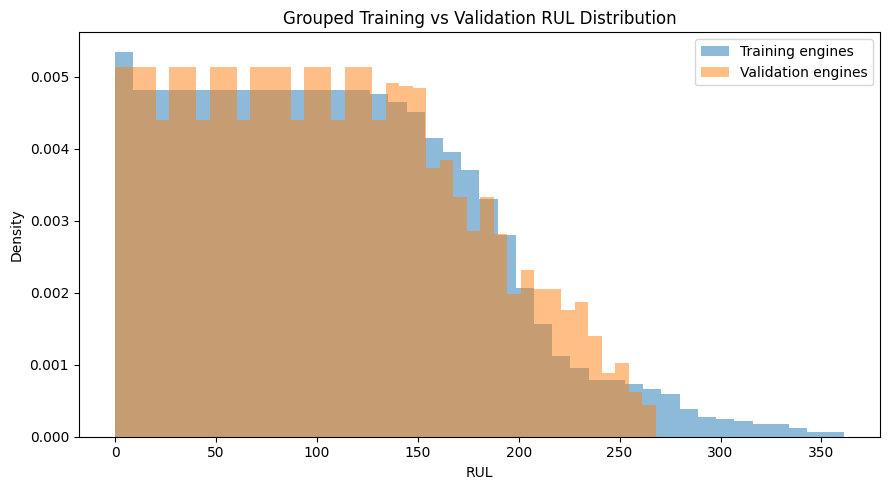

In [38]:
# --- Visualize RUL distributions in grouped training and validation data ---
#
# What this does:
# Compares the target shapes across the two engine populations.
#
# Why this matters:
# This helps us understand the validation sample without changing the split
# merely because the distributions are not perfectly identical.
#
# Concept to focus on:
# We should not repeatedly reshuffle validation until we obtain a split whose
# statistics happen to look especially favorable.

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    y_train,
    bins=40,
    density=True,
    alpha=0.5,
    label="Training engines",
)

plt.hist(
    y_validation,
    bins=40,
    density=True,
    alpha=0.5,
    label="Validation engines",
)

plt.xlabel("RUL")
plt.ylabel("Density")
plt.title(
    "Grouped Training vs Validation RUL Distribution"
)
plt.legend()
plt.tight_layout()
plt.show()

### Do not optimize the validation split itself

A particular grouped holdout may contain somewhat shorter- or longer-lived engines than the fitting population.

That does not automatically make the split invalid.

Repeatedly changing the random seed until validation produces a convenient score or attractive distribution would allow knowledge of the validation set to influence experiment design.

For early pipeline development, a fixed reproducible grouped holdout provides a simple validation boundary.

Later modeling may use grouped cross-validation to evaluate performance across multiple unseen-engine partitions rather than relying entirely on one particular holdout.

### Validation data is not the official test set

The 20 validation engines come from the original run-to-failure training dataset.

Their RUL labels are available because they are development data.

They may therefore be used to:

- compare models,
- evaluate feature engineering,
- select preprocessing,
- and make other modeling decisions.

The official 100 test engines remain completely separate.

Their endpoint RUL labels will still be reserved for final evaluation after model-development decisions are fixed.

In [39]:
# --- Run the final integrity audit for the engine-grouped holdout ---
#
# What this does:
# Combines the most important guarantees established in this task group.
#
# Why this matters:
# Every later preprocessing and modeling experiment will depend on this split
# being statistically and structurally valid.
#
# Concept to focus on:
# The split contract is about engines, alignment, and reproducibility.

assert groups_train.nunique() == 80
assert groups_validation.nunique() == 20

assert set(
    groups_train.unique()
).isdisjoint(
    set(groups_validation.unique())
)

assert (
    len(X_train)
    + len(X_validation)
    == len(X_baseline)
)

assert (
    len(y_train)
    + len(y_validation)
    == len(y_baseline)
)

assert (
    set(train_indices)
    .isdisjoint(set(validation_indices))
)

assert (
    sorted(
        np.concatenate(
            [
                train_indices,
                validation_indices,
            ]
        )
    )
    == list(range(len(X_baseline)))
)

print(
    "Task Group 2 grouped-split integrity checks passed."
)

Task Group 2 grouped-split integrity checks passed.


### Task Group 2 — Interpretation Questions

1. **Why is a conventional random row-level train/validation split inappropriate for FD001, even if the split itself is statistically random?**

Because a conventional random row-level split would create situations where a single engine's rows are scattered between the training set and the validation set. This would allow the model to train on previously seen engines on the validation set, which would inflate and invalidate predictive capabilities. Unique `unit_no`s need to have all their rows remain as a single unit regardless of which set they wind up in for training the model. 

*Can I generalize to an entirely unseen engine?*

2. **What exactly does grouping by `unit_no` guarantee about the relationship between training and validation engines?**

It guarantees that rows associated with any single engine will not wind up in a mix of both sets. Engines need to remain confined to one of the sets in an either/or scheme, not a mixing scheme. 

3. **Why can a 20% validation split contain exactly 20% of the engines but not exactly 20% of the rows?**

Because the number of rows associated with the engines vary. Some engines have longer lifetimes, some engines have shorter lifetimes. 

*Maintaining valid group boundaries matters more than obtaining exact 80/20 row count.*

4. **What does it mean to say that an engine trajectory remains “complete” after the grouped split?**

It means that for any single engine in either the test set or the dev set, it will contain all rows/cycles with no gaps due to rows winding up in the other set. The complete lifecycle of any one engine need to be contained in the training or dev set that it wound up in with no leaks. 

5. **What different roles do `X`, `y`, and `groups` play during the grouped split? Does `unit_no` ever become a predictive feature?**

`X` is inference data. `y` is prediction data. `groups` is boundary data. `unit_no` never becomes a predictive feature, it only gets used to know the boundaries between different engines. 

`X` is predictive features in the form of an input matrix. `y` is the target, i.e., ground-truth labels. `groups` is our grouping metadata.

6. **Why is a fixed `RANDOM_STATE` useful here, and what does reproducibility of the split allow us to do later?**

`RANDOM_STATE` allows us to save the splitting we did for which engines wound up in the train or dev set. If we have that saved, then we we use it to make sure any differing ways of augmenting the data get used on the same split. This makes for more meaningful comparisons between different processes of scaling or editing the data. 

`RANDOM_STATE` doesn't literally save the split. It makes the randomized procedure reproduce the same split when rerun with the same intputs and seed.

7. **If the validation RUL distribution differs somewhat from the training RUL distribution, why shouldn't we automatically keep changing the random seed until they match closely?**

Because the goal is to make a model that can generalize to unforseen data. When it's time to run the model for real we don't get an opportunity to change a random seed until it fits our preferences. 

8. **What is the conceptual difference between the 20 held-out validation engines and the 100 official test engines? What decisions may each influence?**

The 20 held out validation engines are taken directly from the set of 100 official test engines. There is no conceptual difference. 

*The 20 validation engines come from the 100 original training engines, not the official test set.*

*Training fits. Validation chooses. Test judges.*

9. **At the end of Task Group 2, why are we now allowed to fit a scaler on `X_train` but still not allowed to fit it on `X_train` + `X_validation` together?**

Because we need to remain blind to what effects our data augmentations have on the dev set. The training set needs to be our focus. (This is a question I'm shaky on.)

*A scalar isn't just editing the data. It learns parameters from the data.*

*Validation data may pass through a transformation learned from training data. Validation data may not help learn the transformation.*

## Task Group 3: Causal Temporal Feature Foundations

## Task Group 3: Causal Temporal Feature Foundations

### Question

How can historical sensor information be transformed into lag, difference, and trailing-window features without using future observations or allowing one engine's history to contaminate another engine?

### Why this matters

The raw baseline describes an engine only at its current cycle.

However, degradation may also be reflected in how sensor measurements have changed over recent cycles.

Temporal features can capture this history, but they introduce new leakage risks.

A valid temporal feature must satisfy two requirements:

1. **Causal** — at cycle `t`, it may use only observations from cycle `t` or earlier.
2. **Engine-bounded** — it may use history only from the same `unit_no`.

The ordering of observations also matters. A one-cycle lag has the intended meaning only if rows are correctly ordered by engine and cycle.

In [40]:
# --- Reconstruct complete dataframe partitions for temporal feature engineering ---
#
# What this does:
# Uses the grouped split indices from Task Group 2 to create full dataframe
# partitions containing engine identity, cycle order, measurements, and labels.
#
# Why this matters:
# Temporal feature construction needs `unit_no` to preserve engine boundaries
# and `cycles` to preserve chronological order.
#
# Concept to focus on:
# Metadata can be essential to BUILD valid features without itself becoming
# a predictive feature.
#
# `unit_no` helps us construct features correctly.
# It still does not belong in the eventual X matrix.

train_partition_df = (
    train_labeled_df
    .iloc[train_indices]
    .copy()
)

validation_partition_df = (
    train_labeled_df
    .iloc[validation_indices]
    .copy()
)

print("Training partition shape:", train_partition_df.shape)
print("Validation partition shape:", validation_partition_df.shape)

Training partition shape: (16561, 28)
Validation partition shape: (4070, 28)


### Temporal features depend on row order

Operations such as `shift()`, `diff()`, and `rolling()` operate according to the order of rows they receive.

Grouping by `unit_no` prevents one engine from contaminating another, but grouping alone does not guarantee that cycles appear chronologically.

Therefore, temporal feature construction should explicitly sort by:

1. `unit_no`
2. `cycles`

before calculating any historical feature.

For example, if an engine's rows appeared as:

`cycle 1 → cycle 3 → cycle 2`

then a one-row shift would not mean a one-cycle lag.

The pipeline should enforce chronological ordering rather than assuming it.

In [41]:
# --- Put each partition into deterministic engine-cycle order ---
#
# What this does:
# Sorts first by engine identity and then by operating cycle.
#
# Why this matters:
# Temporal operations act on row order. Sorting makes "previous row" mean
# "previous observed cycle within this engine."
#
# Concept to focus on:
# Correct temporal features require BOTH:
#
#   correct engine boundary
#   +
#   correct chronological ordering

train_partition_df = (
    train_partition_df
    .sort_values(["unit_no", "cycles"])
    .copy()
)

validation_partition_df = (
    validation_partition_df
    .sort_values(["unit_no", "cycles"])
    .copy()
)

In [42]:
# --- Verify chronological ordering within the grouped partitions ---
#
# What this does:
# Calculates cycle-to-cycle differences within each engine and confirms every
# observed next row advances exactly one cycle.
#
# Why this matters:
# A lag of one row should correspond to a lag of one operating cycle.
#
# Concept to focus on:
# EDA established sequence integrity globally.
# The pipeline now confirms that our partition/sorting process preserved it.

train_cycle_differences = (
    train_partition_df
    .groupby("unit_no")["cycles"]
    .diff()
    .dropna()
)

validation_cycle_differences = (
    validation_partition_df
    .groupby("unit_no")["cycles"]
    .diff()
    .dropna()
)

assert (train_cycle_differences == 1).all()
assert (validation_cycle_differences == 1).all()

print(
    "Training and validation engine sequences remain consecutive and ordered."
)

Training and validation engine sequences remain consecutive and ordered.


In [43]:
# --- Demonstrate how an ungrouped lag can contaminate engine boundaries ---
#
# What this does:
# Creates both:
# - an unsafe dataframe-wide shift,
# - a safe engine-grouped shift.
#
# Why this matters:
# A normal `.shift(1)` has no understanding of engine identity.
# At the boundary between engines, it can treat the final cycle of one engine
# as the previous observation of the next engine.
#
# Concept to focus on:
# "Previous row" is NOT automatically the same thing as
# "previous cycle from this engine."

lag_boundary_demo = (
    train_partition_df[
        [
            "unit_no",
            "cycles",
            "sensor_measurement_4",
        ]
    ]
    .copy()
)

lag_boundary_demo["unsafe_lag_1"] = (
    lag_boundary_demo["sensor_measurement_4"]
    .shift(1)
)

lag_boundary_demo["safe_lag_1"] = (
    lag_boundary_demo
    .groupby("unit_no")["sensor_measurement_4"]
    .shift(1)
)

In [44]:
# --- Inspect engine-start rows to expose cross-engine lag contamination ---
#
# What this does:
# Shows the first row of several engines for both the unsafe and safe lag.
#
# Why this matters:
# The unsafe shift may populate an engine's first cycle using the previous
# engine's final observation.
#
# Concept to focus on:
# Missing history at an engine boundary is CORRECT.
# Inventing history from another engine is not.

lag_boundary_starts = (
    lag_boundary_demo
    .groupby("unit_no")
    .head(1)
)

lag_boundary_starts.head(10)

,unit_no,cycles,sensor_measurement_4,unsafe_lag_1,safe_lag_1
192,2,1,1391.28,NaN,NaN
479,3,1,1398.13,1430.84,NaN
658,4,1,1402.85,1428.23,NaN
1116,6,1,1412.34,1432.55,NaN
1304,7,1,1395.48,1434.92,NaN
1563,8,1,1409.75,1435.04,NaN
1713,9,1,1396.22,1432.31,NaN
1914,10,1,1392.20,1428.43,NaN
2376,12,1,1402.11,1436.29,NaN
2709,14,1,1403.23,1434.94,NaN


In [45]:
# --- Verify that grouped lag features reset at every engine boundary ---
#
# What this does:
# Checks that every engine's first observation has no one-cycle history.
#
# Why this matters:
# This assertion proves that no lag value was borrowed from another engine.
#
# Concept to focus on:
# A NaN here is not dirty data.
# It correctly represents unavailable historical information.

safe_engine_starts = (
    lag_boundary_demo
    .groupby("unit_no")
    .head(1)
)

assert (
    safe_engine_starts["safe_lag_1"]
    .isna()
    .all()
)

print(
    "Grouped lag correctly resets at every engine boundary."
)

Grouped lag correctly resets at every engine boundary.


### Lag features

A lag preserves a previous sensor value as a new feature.

For example:

| cycle | Sensor 4 | Sensor 4 lag 1 |
|---:|---:|---:|
| 1 | 100 | missing |
| 2 | 104 | 100 |
| 3 | 107 | 104 |
| 4 | 109 | 107 |

At cycle 4:

- current Sensor 4 = 109
- one-cycle lag = 107

The lag gives the model historical context.

Two engines can have the same current sensor value but have arrived there through different recent histories.

### Difference features

A first difference measures the change between the current and previous cycle:

`difference_1 = current_value - previous_value`

For example:

| cycle | Sensor | Difference |
|---:|---:|---:|
| 1 | 100 | missing |
| 2 | 104 | +4 |
| 3 | 107 | +3 |
| 4 | 109 | +2 |

A lag asks:

"What was the previous value?"

A difference asks:

"How much did the sensor just change?"

Both are causal because they use only current and historical observations.

In [46]:
# --- Demonstrate a causal within-engine first-difference feature ---
#
# What this does:
# Calculates current Sensor 4 minus its previous-cycle value separately
# within each engine.
#
# Why this matters:
# A current reading may be more informative when accompanied by the rate or
# direction of its recent movement.
#
# Concept to focus on:
# `.groupby(...).diff()` automatically resets at engine boundaries.
# The first observation has no previous value and therefore produces NaN.

difference_demo = (
    train_partition_df[
        [
            "unit_no",
            "cycles",
            "sensor_measurement_4",
        ]
    ]
    .copy()
)

difference_demo["sensor_4_diff_1"] = (
    difference_demo
    .groupby("unit_no")["sensor_measurement_4"]
    .diff(1)
)

difference_demo.head(10)

,unit_no,cycles,sensor_measurement_4,sensor_4_diff_1
192,2,1,1391.28,NaN
193,2,2,1393.13,1.85
194,2,3,1398.96,5.83
195,2,4,1396.08,-2.88
196,2,5,1402.52,6.44
197,2,6,1396.76,-5.76
198,2,7,1400.65,3.89
199,2,8,1395.39,-5.26
200,2,9,1395.01,-0.38
201,2,10,1394.86,-0.15


In [47]:
# --- Verify the mathematical meaning of the first-difference feature ---
#
# What this does:
# Selects one training engine and manually checks the computed differences
# against current minus previous Sensor 4 values.
#
# Why this matters:
# Feature engineering code should be validated against the quantity we think
# it represents rather than trusted simply because pandas returned numbers.
#
# Concept to focus on:
# Always connect an engineered column back to its mathematical definition.

example_unit = (
    train_partition_df["unit_no"]
    .iloc[0]
)

example_difference = (
    difference_demo
    .loc[
        difference_demo["unit_no"] == example_unit
    ]
    .head(6)
    .copy()
)

example_difference

,unit_no,cycles,sensor_measurement_4,sensor_4_diff_1
192,2,1,1391.28,NaN
193,2,2,1393.13,1.85
194,2,3,1398.96,5.83
195,2,4,1396.08,-2.88
196,2,5,1402.52,6.44
197,2,6,1396.76,-5.76


In [48]:
# --- Assert that the difference feature equals current minus previous value ---
#
# What this does:
# Independently reconstructs the expected first difference for the example
# engine and checks it against the engineered feature.
#
# Why this matters:
# This provides a small unit-test-like verification of feature semantics.

expected_difference = (
    example_difference["sensor_measurement_4"]
    - example_difference["sensor_measurement_4"].shift(1)
)

assert np.allclose(
    example_difference["sensor_4_diff_1"],
    expected_difference,
    equal_nan=True,
)

print(
    "Sensor 4 first-difference semantics verified."
)

Sensor 4 first-difference semantics verified.


### Trailing rolling features

A rolling feature summarizes a recent historical window.

For a 5-cycle trailing mean at cycle 100, the legal window is:

`cycles 96, 97, 98, 99, 100`

This window is causal because every included observation is available when the prediction at cycle 100 is made.

A centered window such as:

`cycles 98, 99, 100, 101, 102`

would leak future observations and is therefore invalid.

Trailing statistics can summarize properties such as:

- recent average level,
- recent variability,
- minimum or maximum,
- and eventually recent trend.

In this task group we will use a rolling mean only to establish the mechanics.

In [49]:
# --- Demonstrate a causal five-cycle trailing rolling mean ---
#
# What this does:
# Computes the mean of Sensor 4 over the current cycle and previous four cycles,
# separately for each engine.
#
# Why this matters:
# A trailing mean can smooth short-term noise and represent the sensor's recent
# underlying level.
#
# Concept to focus on:
# - `groupby("unit_no")` prevents cross-engine contamination.
# - `rolling(window=5)` looks backward through row order.
# - `min_periods=5` requires a full history before producing a value.
#
# Therefore, the first four cycles of every engine SHOULD be missing.

rolling_demo = (
    train_partition_df[
        [
            "unit_no",
            "cycles",
            "sensor_measurement_4",
        ]
    ]
    .copy()
)

rolling_demo["sensor_4_rolling_mean_5"] = (
    rolling_demo
    .groupby("unit_no")["sensor_measurement_4"]
    .transform(
        lambda series: (
            series
            .rolling(
                window=5,
                min_periods=5,
            )
            .mean()
        )
    )
)

rolling_demo.head(10)

,unit_no,cycles,sensor_measurement_4,sensor_4_rolling_mean_5
192,2,1,1391.28,NaN
193,2,2,1393.13,NaN
194,2,3,1398.96,NaN
195,2,4,1396.08,NaN
196,2,5,1402.52,1396.394
197,2,6,1396.76,1397.490
198,2,7,1400.65,1398.994
199,2,8,1395.39,1398.280
200,2,9,1395.01,1398.066
201,2,10,1394.86,1396.534


In [50]:
# --- Manually verify the first available five-cycle rolling mean ---
#
# What this does:
# Finds the first five observations from one engine, computes their Sensor 4
# mean manually, and compares it with the engineered rolling value at cycle 5.
#
# Why this matters:
# Rolling-window code can look compact while hiding important window semantics.
# Manual verification ensures the window includes exactly the observations
# we intend.

example_rolling = (
    rolling_demo
    .loc[
        rolling_demo["unit_no"] == example_unit
    ]
    .head(5)
    .copy()
)

manual_rolling_mean = (
    example_rolling["sensor_measurement_4"]
    .mean()
)

engineered_rolling_mean = (
    example_rolling[
        "sensor_4_rolling_mean_5"
    ]
    .iloc[-1]
)

print(
    "Manual five-cycle mean:",
    manual_rolling_mean,
)

print(
    "Engineered five-cycle mean:",
    engineered_rolling_mean,
)

assert np.isclose(
    manual_rolling_mean,
    engineered_rolling_mean,
)

Manual five-cycle mean: 1396.3939999999998
Engineered five-cycle mean: 1396.394


In [51]:
# --- Verify the expected boundary missingness created by a full rolling window ---
#
# What this does:
# Checks that cycles 1-4 of every engine have no five-cycle rolling mean and
# that cycle 5 is the first cycle where the statistic becomes available.
#
# Why this matters:
# These NaNs are mathematically correct consequences of insufficient history,
# not data-quality defects.
#
# Concept to focus on:
# Temporal feature engineering can CREATE missing values even when the raw
# dataset contains none.

rolling_first_five = (
    rolling_demo
    .groupby("unit_no")
    .head(5)
)

assert (
    rolling_first_five
    .loc[
        rolling_first_five["cycles"] < 5,
        "sensor_4_rolling_mean_5",
    ]
    .isna()
    .all()
)

assert (
    rolling_first_five
    .loc[
        rolling_first_five["cycles"] == 5,
        "sensor_4_rolling_mean_5",
    ]
    .notna()
    .all()
)

print(
    "Five-cycle rolling-window boundary behavior verified."
)

Five-cycle rolling-window boundary behavior verified.


### Future-looking shifts are leakage

The sign of a shift matters.

For an ordered engine sequence:

`shift(1)`

means:

"give the current row the previous row's value."

That is a causal lag.

By contrast:

`shift(-1)`

means:

"give the current row the next row's value."

At cycle 100, `shift(-1)` would provide the measurement from cycle 101.

That observation does not exist yet when the cycle-100 prediction is made, so it is future-information leakage.

### The current observation is legal

A causal feature does not have to use only cycles strictly before `t`.

When making a prediction at cycle `t`, the current cycle's operating settings and sensor measurements are assumed to be available.

Therefore a trailing window may include the current observation.

For example, at cycle 100:

`mean(cycles 96-100)`

is causal.

The forbidden boundary begins after the prediction point:

`cycle > 100`

### Temporal transformations after grouped splitting

Lag, difference, and trailing-window calculations do not learn fleet-wide parameters such as a scaler mean or PCA direction.

When they are strictly causal and grouped by engine, they can be computed without using another engine's information.

For pipeline clarity, we will apply temporal transformations independently to the training and validation partitions.

This reinforces two boundaries:

- training engines never provide history for validation engines,
- validation engines never provide history for training engines.

Within a validation engine, however, its own previous observations are legitimate inputs because those observations would also be available when predicting that operating engine in practice.

In [52]:
# --- Verify the reusable lag utility on one representative sensor ---
#
# What this does:
# Uses the new source-code utility to create a one-cycle Sensor 4 lag.
#
# Why this matters:
# We first learned the mechanics directly with pandas. Now we verify that the
# reusable implementation preserves those same semantics.
#
# Concept to focus on:
# Reusable abstraction should come AFTER understanding the underlying
# operation, not instead of understanding it.

from predictive_maintenance.features.temporal import (
    add_difference_features,
    add_lag_features,
    add_rolling_mean_features,
)

train_lag_demo = add_lag_features(
    train_partition_df,
    columns=[
        "sensor_measurement_4",
    ],
    lags=[
        1,
    ],
)

train_lag_demo[
    [
        "unit_no",
        "cycles",
        "sensor_measurement_4",
        "sensor_measurement_4_lag_1",
    ]
].head(10)

,unit_no,cycles,sensor_measurement_4,sensor_measurement_4_lag_1
192,2,1,1391.28,NaN
193,2,2,1393.13,1391.28
194,2,3,1398.96,1393.13
195,2,4,1396.08,1398.96
196,2,5,1402.52,1396.08
197,2,6,1396.76,1402.52
198,2,7,1400.65,1396.76
199,2,8,1395.39,1400.65
200,2,9,1395.01,1395.39
201,2,10,1394.86,1395.01


In [53]:
# --- Verify that the reusable lag utility remains engine-bounded ---
#
# What this does:
# Checks that the first cycle of every training engine still has no lag value.
#
# Why this matters:
# This is one of the central invariants every future temporal feature utility
# must preserve.

lag_first_rows = (
    train_lag_demo
    .groupby("unit_no")
    .head(1)
)

assert (
    lag_first_rows[
        "sensor_measurement_4_lag_1"
    ]
    .isna()
    .all()
)

print(
    "Reusable lag utility preserves engine boundaries."
)

Reusable lag utility preserves engine boundaries.


### What Task Group 3 established

We now have a validated foundation for causal temporal feature engineering.

A legal temporal feature must:

- operate on correctly ordered engine sequences,
- remain within a single `unit_no`,
- use only current or previous observations,
- and represent unavailable early history honestly rather than borrowing information from another engine or the future.

We established the mechanics of:

- lag features,
- first differences,
- and trailing rolling means.

We have **not** established that these features improve RUL prediction.

We have also not yet decided:

- which sensors should receive temporal features,
- which lag lengths to use,
- which rolling-window sizes to use,
- or how to handle the structural missing values produced near engine starts.

Those are downstream pipeline and modeling decisions.

### Task Group 3 — Interpretation Questions

1. **What are the two fundamental requirements that every temporal feature must satisfy to be legal for this project?**

Every temporal feature must be causal and group-bounded. Causal means that the feature only has access to current and past data, never future data. Group-bounded means each engine only has access to its own data, never from other engines in the fleet.

2. **Why is `groupby("unit_no")` necessary when creating lag, difference, or rolling features? What could happen without it?**

The lag, difference, and rolling features could cross into engine data that doesn't belong to that particular engine. That would be a violation of one of the two fundamental requirements. 

3. **Why must observations be sorted by both `unit_no` and `cycles` before temporal features are calculated?**

Sorting by `unit_no` enables us to make sure all unique engines don't have overlapping rows in the data. This helps with making sure all features are group-bounded. Sorting by `cycles` ensures all features are constructed by only current and past data. This helps with making sure all features are causal.

*Sorting by `unit_no` does not itself prevent cross-engine contamination. `groupby("unit_no")` does that.*

*Sorting by `cycles` does not itself guarantee causality.*

4. **Conceptually, what different information do a lag feature, a difference feature, and a trailing rolling mean provide?**

Lag provides the data from cycles in the immediate past. Difference provides data on the magnitude of recent changes in the data. Trailing rolling mean provides the mean of the data from the immediate past. 

5. **Why should the first row of every engine have a missing one-cycle lag and first difference? Why is that missingness not a data-quality defect?**

Because lag and difference is calculated from the data of previous cycles. For the first row of each engine its at the start of its lifecycle and that data doesn't exist yet. This missingness is not a quality defect because if there were established values at the first row for those features, then we would have a violation of causality. 

*The NaN is structurally correct because the historical value does not exist.*

6. **Why is `shift(1)` potentially legal while `shift(-1)` creates leakage?**

`shift(1)` fetches information from the immediate past. `shift(-1)` fetches data from the immediate future. The former is legal and does not violate causality. The later is illegal and violets causality, also creating leakage.

7. **At cycle 100, why is a rolling mean over cycles 96-100 legal while a centered window over cycles 98-102 is not?**

At cycle 100 causality requires that the feature only has access to data from cycle 100 and earlier, never in the future. If the window extends past 100 and over to 102 then we have a violation of causality on our hands. 

8. **Why is it legitimate to use cycles 1-99 from a validation engine when constructing a temporal feature for cycle 100 of that same validation engine?**

Because neither of the temporal feature requirements is being violated in this scenario. Cycles 1-99 will belong specifically to that engine, and these cycles are also all in the past. 

9. **What has Task Group 3 actually established, and what have we deliberately not concluded yet about temporal features?**

Task Group 3 has established mechanisms for forming temporal features. We have not deliberately concluded which features will be useful and which won't. (I don't feel confident in my ability to answer this one.)

*We established the validity rules for forming temporal features and we verified their implementations.*

*We've established correctness. We have not established usefulness.*

**We now know how to create valid temporal features. We have not yet shown that any of them improve the model.**

## Task Group 4: Simple Baseline Temporal Features

## Task Group 4: Simple Baseline Temporal Features

### Question

Which small set of causal temporal features should be constructed as the first extension of the raw FD001 feature set, and how can we guarantee that exactly the same feature definitions are applied to training, validation, and eventual test data?

### Why this matters

EDA showed that several sensors change systematically as engines progress through their lifecycles.

The raw baseline captures only the current state of an engine. Temporal features can add information about:

- what a sensor measured recently,
- how quickly it just changed,
- and what its recent underlying level has been.

However, creating every possible lag, window, and statistic would generate a large feature space without evidence that those choices are useful.

The first temporal feature set will therefore be intentionally small and based on sensors that showed especially strong lifecycle-associated behavior during EDA.

This creates a clean first experiment:

**Raw model**
→ current engine state only

versus

**Simple temporal model**
→ current engine state + limited recent sensor history

In [54]:
# --- Import and inspect the simple temporal feature policy ---
#
# What this does:
# Loads the EDA-motivated source sensors and exact engineered-feature names
# from reusable project source code.
#
# Why this matters:
# Train, validation, and test must all use exactly the same temporal feature
# definitions. We do not want separate notebook cells manually deciding what
# each dataset receives.
#
# Concept to focus on:
# Feature engineering itself has a schema contract just like raw features do.

from predictive_maintenance.features.feature_sets import (
    SIMPLE_TEMPORAL_FEATURES,
    SIMPLE_TEMPORAL_LAGS,
    SIMPLE_TEMPORAL_MODEL_FEATURES,
    SIMPLE_TEMPORAL_WINDOWS,
    TEMPORAL_SOURCE_FEATURES,
)

print(
    "Temporal source sensors:",
    len(TEMPORAL_SOURCE_FEATURES),
)

print(
    "Engineered temporal features:",
    len(SIMPLE_TEMPORAL_FEATURES),
)

print(
    "Total simple temporal model features:",
    len(SIMPLE_TEMPORAL_MODEL_FEATURES),
)

Temporal source sensors: 6
Engineered temporal features: 18
Total simple temporal model features: 36


In [55]:
# --- Display every engineered feature in the simple temporal contract ---
#
# What this does:
# Makes the temporal feature definitions visible rather than treating the
# expanded dataframe as an opaque collection of columns.
#
# Why this matters:
# Every engineered feature should have a meaning we can explain.
#
# Concept to focus on:
# We are adding three different kinds of historical information:
#
# lag            → previous state
# difference     → most recent movement
# rolling mean   → recent underlying level

for feature in SIMPLE_TEMPORAL_FEATURES:
    print(feature)

sensor_measurement_4_lag_1
sensor_measurement_7_lag_1
sensor_measurement_9_lag_1
sensor_measurement_11_lag_1
sensor_measurement_12_lag_1
sensor_measurement_14_lag_1
sensor_measurement_4_diff_1
sensor_measurement_7_diff_1
sensor_measurement_9_diff_1
sensor_measurement_11_diff_1
sensor_measurement_12_diff_1
sensor_measurement_14_diff_1
sensor_measurement_4_rolling_mean_5
sensor_measurement_7_rolling_mean_5
sensor_measurement_9_rolling_mean_5
sensor_measurement_11_rolling_mean_5
sensor_measurement_12_rolling_mean_5
sensor_measurement_14_rolling_mean_5


### Why the first temporal feature set is intentionally small

There are many possible temporal feature choices.

For example, we could immediately create:

- lag 1,
- lag 5,
- lag 10,
- lag 20,
- rolling mean 5,
- rolling mean 10,
- rolling mean 20,
- rolling standard deviation,
- rolling minimum,
- rolling maximum,
- rolling slopes,
- exponentially weighted statistics,
- and many others.

Doing all of that immediately would make it difficult to determine which ideas actually improve generalization.

Instead, the first temporal representation uses only:

- one-cycle lag,
- one-cycle difference,
- five-cycle trailing mean.

These choices are not assumed to be optimal.

They provide a small, interpretable starting point that can later be expanded through controlled validation experiments.

In [56]:
# --- Import the reusable simple temporal feature builder ---
#
# What this does:
# Loads the single transformation responsible for constructing our first
# temporal feature representation.
#
# Why this matters:
# Having one implementation reduces the chance that training and validation
# receive subtly different transformations.
#
# Concept to focus on:
# Training/inference consistency is part of feature engineering correctness.

from predictive_maintenance.features.temporal import (
    add_simple_temporal_features,
)

In [57]:
# --- Create the same temporal representation independently in each partition ---
#
# What this does:
# Adds identical lag, difference, and trailing-mean features to the grouped
# training and validation engine histories.
#
# Why this matters:
# Both populations need the same feature definitions while preserving their
# independent engine boundaries.
#
# Concept to focus on:
# Validation engines may use THEIR OWN previously observed history.
# They must never borrow history from training engines or future cycles.

train_temporal_df = add_simple_temporal_features(
    train_partition_df
)

validation_temporal_df = add_simple_temporal_features(
    validation_partition_df
)

In [58]:
# --- Apply the same causal temporal transformation to official test histories ---
#
# What this does:
# Constructs the same engineered feature columns for the truncated test engine
# trajectories.
#
# Why this matters:
# The eventual model must receive the same feature definitions at inference
# time that it saw during development.
#
# Concept to focus on:
# Test HISTORY is legal inference information.
# Test RUL LABELS remain sealed evaluation information.

test_temporal_df = add_simple_temporal_features(
    test_df
)

In [59]:
# --- Inspect how raw and engineered values coexist for one training engine ---
#
# What this does:
# Displays Sensor 4 together with its lag, difference, and rolling mean.
#
# Why this matters:
# Engineered features should remain interpretable in terms of the original
# sequence rather than becoming anonymous columns.
#
# Concept to focus on:
# At each cycle, the new features answer different questions about Sensor 4.

example_unit = (
    train_temporal_df["unit_no"]
    .iloc[0]
)

example_temporal_rows = (
    train_temporal_df
    .loc[
        train_temporal_df["unit_no"]
        == example_unit,
        [
            "unit_no",
            "cycles",
            "sensor_measurement_4",
            "sensor_measurement_4_lag_1",
            "sensor_measurement_4_diff_1",
            "sensor_measurement_4_rolling_mean_5",
        ],
    ]
    .head(10)
)

example_temporal_rows

,unit_no,cycles,sensor_measurement_4,sensor_measurement_4_lag_1,sensor_measurement_4_diff_1,sensor_measurement_4_rolling_mean_5
192,2,1,1391.28,NaN,NaN,NaN
193,2,2,1393.13,1391.28,1.85,NaN
194,2,3,1398.96,1393.13,5.83,NaN
195,2,4,1396.08,1398.96,-2.88,NaN
196,2,5,1402.52,1396.08,6.44,1396.394
197,2,6,1396.76,1402.52,-5.76,1397.490
198,2,7,1400.65,1396.76,3.89,1398.994
199,2,8,1395.39,1400.65,-5.26,1398.280
200,2,9,1395.01,1395.39,-0.38,1398.066
201,2,10,1394.86,1395.01,-0.15,1396.534


In [60]:
# --- Verify that first differences agree with current minus lagged values ---
#
# What this does:
# Reconstructs every Sensor 4 first difference from the raw current value and
# one-cycle lag and compares it with the engineered difference column.
#
# Why this matters:
# Different temporal features are mathematically related. Verifying those
# relationships gives us stronger confidence in feature semantics.
#
# Concept to focus on:
# A difference is not an unrelated new measurement.
# It is a representation of CHANGE derived from current and past state.

expected_sensor_4_difference = (
    train_temporal_df["sensor_measurement_4"]
    - train_temporal_df[
        "sensor_measurement_4_lag_1"
    ]
)

assert np.allclose(
    train_temporal_df[
        "sensor_measurement_4_diff_1"
    ],
    expected_sensor_4_difference,
    equal_nan=True,
)

print(
    "Sensor 4 current/lag/difference relationship verified."
)

Sensor 4 current/lag/difference relationship verified.


In [61]:
# --- Construct the 36-column temporal modeling matrices ---
#
# What this does:
# Selects:
#
# 18 raw baseline predictors
# +
# 18 approved temporal predictors
#
# from the engineered dataframes.
#
# Why this matters:
# The full temporal dataframe still contains metadata and targets that must not
# enter model fitting.
#
# Concept to focus on:
# Feature engineering does NOT eliminate the need for an explicit allowlist.

X_train_temporal = train_temporal_df[
    SIMPLE_TEMPORAL_MODEL_FEATURES
].copy()

X_validation_temporal = validation_temporal_df[
    SIMPLE_TEMPORAL_MODEL_FEATURES
].copy()

X_test_temporal = test_temporal_df[
    SIMPLE_TEMPORAL_MODEL_FEATURES
].copy()

In [62]:
# --- Compare raw and temporally enriched feature-matrix dimensions ---
#
# What this does:
# Shows exactly how much additional representation the simple temporal policy
# has introduced.
#
# Why this matters:
# Feature engineering increases model complexity even before the model itself
# changes.
#
# Concept to focus on:
# Raw and temporal models will describe the same engine-cycle rows using
# different amounts of information.

print(
    "Raw training matrix:",
    X_train.shape,
)

print(
    "Temporal training matrix:",
    X_train_temporal.shape,
)

print(
    "Raw validation matrix:",
    X_validation.shape,
)

print(
    "Temporal validation matrix:",
    X_validation_temporal.shape,
)

print(
    "Temporal test matrix:",
    X_test_temporal.shape,
)

Raw training matrix: (16561, 18)
Temporal training matrix: (16561, 36)
Raw validation matrix: (4070, 18)
Temporal validation matrix: (4070, 36)
Temporal test matrix: (13096, 36)


In [63]:
# --- Verify identical engineered schemas across training, validation, and test ---
#
# What this does:
# Checks both feature identity and column ordering.
#
# Why this matters:
# The model must encounter the same interpretation of every input position
# during fitting and inference.
#
# Concept to focus on:
# Temporal feature engineering is part of the train/inference contract.

assert (
    X_train_temporal.columns.tolist()
    == X_validation_temporal.columns.tolist()
)

assert (
    X_train_temporal.columns.tolist()
    == X_test_temporal.columns.tolist()
)

assert len(
    X_train_temporal.columns
) == 36

print(
    "Training, validation, and test temporal schemas match."
)

Training, validation, and test temporal schemas match.


In [64]:
# --- Verify that temporal matrices still contain only approved predictors ---
#
# What this does:
# Confirms that the expanded feature matrices do not contain targets,
# identifiers, failure endpoints, or other non-predictive metadata.
#
# Why this matters:
# Creating more dataframe columns increases the opportunity for an accidental
# leaking column to enter X.
#
# Concept to focus on:
# Leakage checks should be repeated after meaningful transformations, not
# assumed to remain true forever.

forbidden_temporal_overlap = (
    set(X_train_temporal.columns)
    .intersection(NON_PREDICTIVE_COLUMNS)
)

assert not forbidden_temporal_overlap, (
    "Forbidden temporal inputs detected: "
    f"{sorted(forbidden_temporal_overlap)}"
)

print(
    "Temporal feature matrix contains no known forbidden columns."
)

Temporal feature matrix contains no known forbidden columns.


In [65]:
# --- Quantify structurally missing values created by temporal features ---
#
# What this does:
# Counts NaNs in each engineered temporal feature for training data.
#
# Why this matters:
# Historical features cannot exist until enough engine history has accumulated.
#
# Concept to focus on:
# Missing does not automatically mean corrupted.
# Here, missing values encode "this history does not exist yet."

temporal_missing_summary = (
    X_train_temporal[
        SIMPLE_TEMPORAL_FEATURES
    ]
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
)

temporal_missing_summary

sensor_measurement_14_rolling_mean_5    320
sensor_measurement_12_rolling_mean_5    320
sensor_measurement_11_rolling_mean_5    320
sensor_measurement_9_rolling_mean_5     320
sensor_measurement_7_rolling_mean_5     320
sensor_measurement_4_rolling_mean_5     320
sensor_measurement_7_lag_1               80
sensor_measurement_14_diff_1             80
sensor_measurement_12_diff_1             80
sensor_measurement_4_lag_1               80
sensor_measurement_9_diff_1              80
sensor_measurement_7_diff_1              80
sensor_measurement_4_diff_1              80
sensor_measurement_14_lag_1              80
sensor_measurement_12_lag_1              80
sensor_measurement_11_lag_1              80
sensor_measurement_9_lag_1               80
sensor_measurement_11_diff_1             80
dtype: int64

In [66]:
# --- Count how many engine-cycle rows contain at least one temporal NaN ---
#
# What this does:
# Measures how many rows are not yet complete under the 36-feature temporal
# representation.
#
# Why this matters:
# We need to understand the scale of the boundary problem before deciding
# whether to drop, impute, or otherwise represent missing history.
#
# Concept to focus on:
# This cell DESCRIBES the problem.
# It does not yet choose a missing-value policy.

train_rows_with_temporal_nan = (
    X_train_temporal
    .isna()
    .any(axis=1)
    .sum()
)

validation_rows_with_temporal_nan = (
    X_validation_temporal
    .isna()
    .any(axis=1)
    .sum()
)

test_rows_with_temporal_nan = (
    X_test_temporal
    .isna()
    .any(axis=1)
    .sum()
)

print(
    "Training rows with temporal NaN:",
    train_rows_with_temporal_nan,
)

print(
    "Validation rows with temporal NaN:",
    validation_rows_with_temporal_nan,
)

print(
    "Test rows with temporal NaN:",
    test_rows_with_temporal_nan,
)

Training rows with temporal NaN: 320
Validation rows with temporal NaN: 80
Test rows with temporal NaN: 400


In [67]:
# --- Verify that temporal missingness is confined to early engine history ---
#
# What this does:
# Inspects the maximum cycle number among rows containing any temporal NaN.
#
# Why this matters:
# With the current feature policy, all temporal features should be available
# once an engine reaches cycle 5.
#
# Concept to focus on:
# Unexpected NaNs later in an engine's lifecycle would suggest a feature-
# engineering bug or underlying data problem rather than normal boundary
# behavior.

train_temporal_nan_mask = (
    X_train_temporal
    .isna()
    .any(axis=1)
)

train_nan_cycles = (
    train_temporal_df.loc[
        train_temporal_nan_mask,
        "cycles",
    ]
)

print(
    "Largest cycle with temporal missingness:",
    train_nan_cycles.max(),
)

assert (
    train_nan_cycles.max()
    == 4
)

print(
    "Temporal NaNs are confined to cycles 1-4."
)

Largest cycle with temporal missingness: 4
Temporal NaNs are confined to cycles 1-4.


### Creating a feature does not mean the feature has been selected

The pipeline now knows how to generate 18 simple temporal features.

That does not mean all 18 belong in the final model.

The distinction is:

**Feature generation**
→ construct plausible candidate information correctly

**Feature selection**
→ determine through validation whether that information improves generalization

For example, Sensor 9's one-cycle lag may turn out to help while its rolling mean may not.

Likewise, a temporal model may fail to outperform the raw baseline.

Those are modeling results that cannot be established from pipeline correctness alone.

### Temporal feature engineering is not data augmentation

The temporal transformation does not create additional engine-cycle observations.

The same rows still exist.

Instead, each row is represented with additional columns describing its available history.

For example:

Raw cycle-100 representation:

`current Sensor 4`

Temporally enriched cycle-100 representation:

- `current Sensor 4`
- `Sensor 4 at cycle 99`
- `change from cycle 99 to 100`
- `mean Sensor 4 over cycles 96-100`

This increases feature dimensionality, not sample count.

In [68]:
# --- Run the final integrity audit for the simple temporal feature set ---
#
# What this does:
# Verifies feature counts, schema consistency, row preservation, and expected
# missing-history behavior.
#
# Why this matters:
# Task Group 5 should begin from a known-good temporal representation.
#
# Concept to focus on:
# We have established that these features are correctly constructed.
# We have NOT established that they improve prediction.

assert len(
    TEMPORAL_SOURCE_FEATURES
) == 6

assert len(
    SIMPLE_TEMPORAL_FEATURES
) == 18

assert len(
    SIMPLE_TEMPORAL_MODEL_FEATURES
) == 36

assert len(
    X_train_temporal
) == len(
    X_train
)

assert len(
    X_validation_temporal
) == len(
    X_validation
)

assert (
    X_train_temporal.columns.tolist()
    == X_validation_temporal.columns.tolist()
    == X_test_temporal.columns.tolist()
)

assert not set(
    NON_PREDICTIVE_COLUMNS
).intersection(
    X_train_temporal.columns
)

assert (
    train_nan_cycles.max()
    == 4
)

print(
    "Task Group 4 temporal-feature integrity checks passed."
)

Task Group 4 temporal-feature integrity checks passed.


### Task Group 4 — Interpretation Questions

1. **Why did we choose Sensors 4, 7, 9, 11, 12, and 14 as the first temporal source sensors, and what have we *not* proven about them yet?**

Sensors 4, 7, 9, 11, 12, and 14 showed changes with time, making them good candidates for feature engineeing because engine failure is something we know to become more likely as number of cycles increases. We have not yet proven that they make meaningful contributions to predictive capabilities. That is something that we need to run experiments to confirm. 

*These six sensors showed comparatively strong and consistent within-engine lifecycle-associated behavior during EDA. That makes thei recent hsitory plausible candidate information, but we have not shown that they added predictive information beyond current values and cycle count.*

2. **What three temporal feature types are being added for each source sensor, and what distinct information does each represent?**

We're adding lag, which gives a measure of the sensor reading immediately before the one at the current cycle. We're adding difference, which measures how much the current sensor reading changed relative to its last reading. And we're adding rolling mean, which measures the average of a past set of sequential values that were measured directly before the current cycle. 

3. **How do 6 temporal source sensors produce 18 engineered features and a 36-feature total model representation?**

There are a total of 18 input features in our baseline feature set. From those we picked 6 that we suspect are good candidates for forming engineered features. For each of those 6, we created 3 engineered features. In total that gives us 18 + 6*3 = 36 total features.

4. **Why are we deliberately using only lag 1, difference 1, and a five-cycle rolling mean instead of immediately generating many different lag/window/statistic combinations?**

(Not sure how to confidently answer this one.) We are choosing small windows because that's all it should take to discern if these engineered features make a difference in a model's predictive capabilities. Larger windows would be overkill and use up more resources than we should be allocating at this time in the development process. If any of these features causes a big difference in prediction metrics, then we can go back and experiment with making the windows larger. 

*We start with a small, interpretable feature set so temporal complexity can earn its place through controlled experiments. The lag and window choices are reference choices, not claims that they are optimal or sufficient.*

5. **Why can the same temporal feature builder legally be applied to validation and test engines even though those engines were not used to fit the model?**

Because the input feature matrix for the validation and test engines needs to be matched to the training set. Otherwise the inputs won't be compatible with the model's scheme of mapping inputs to targets. 

*An unseen engine can still have an observed history.*

*The builder can legally be applied to validation and test engines because it uses only each engine's own current and previously observed history. That information would exist at inference time. The transformation must also be identical to across train, validation, and test so that all three populations share the same feature definition.*

6. **Why does temporal feature engineering create NaNs even though the raw FD001 data contained no missing values, and why should those NaNs be concentrated in cycles 1-4?**

Because our fundamental rules for temporal features is that they must be causal and group-bounded. When dealing with a window that goes back 5 measurements in previous cycles, at the start of an engine's lifetime those measurements will not have come into existence yet. 

7. **What is the difference between generating a candidate temporal feature and establishing that the feature is actually useful for RUL prediction?**

Generating candidate temporal features simply comes from hypothesizing which certain engineered features will make meaningful impacts to predictive capabilities. Determining if they are actually useful cannot be done until a model has been trained and we can check on prediction metrics.

*Does this feature improve performance on unseen validation engines under an otherwise controlled comparison?*

8. **Why is temporal feature engineering not the same thing as data augmentation?**

Because our baseline set of features is still in the dataset. Instead of modifying existing columns, we use them to make calculations for adding new columns. The baseline feature set stays the same and new columns get appended to the existing dataset.

*Feature engineering changes how each observation is represented. Data augmentation increases or synthesizes observations.*

9. **At the end of Task Group 4, what is now ready for modeling, and what issue still prevents us from immediately fitting every estimator to `X_train_temporal`?**

Our set of 18 baseline raw features and 18 engineered features is ready for modeling. (I'm not sure how to confidently answer this question past that.)

*We have correctly generated 36-feature temporal representation with matching train, validation, and test schemas. However, temporal features create structurally missing values near engine starts, so we still need to decide how those missing values should be handled before the matrix is suitable for every estimator.*

## Task Group 5: Temporal Boundary & Missing-value Handling

## Task Group 5: Temporal Boundary & Missing-Value Handling

### Question

How should the pipeline handle temporal features that are unavailable near the beginning of each engine trajectory without introducing leakage, inventing nonexistent history, or making unfair comparisons between raw and temporal models?

### Why this matters

The raw FD001 files contained no missing measurements, but temporal feature engineering intentionally created missing values.

With the current temporal policy:

- `lag_1` is unavailable at cycle 1,
- `diff_1` is unavailable at cycle 1,
- `rolling_mean_5` is unavailable at cycles 1–4.

These values are missing because the required engine history does not yet exist.

This is structural missingness rather than evidence of corrupted raw data.

The pipeline therefore needs an explicit boundary policy rather than treating these NaNs as ordinary data-quality defects.

In [69]:
# --- Re-establish target and group alignment after temporal sorting ---
#
# What this does:
# Extracts y and groups directly from the same sorted dataframes used to
# generate the temporal X matrices.
#
# Why this matters:
# Temporal feature functions sort rows by engine and cycle. If X changes row
# order while y does not, model.fit(X, y) could silently pair features with
# the wrong targets.
#
# Concept to focus on:
# Matching row COUNTS is not enough.
# X and y must describe the exact same observations in the exact same order.

y_train_temporal_full = train_temporal_df[
    TARGET_COLUMN
].copy()

groups_train_temporal_full = train_temporal_df[
    GROUP_COLUMN
].copy()

y_validation_temporal_full = validation_temporal_df[
    TARGET_COLUMN
].copy()

groups_validation_temporal_full = validation_temporal_df[
    GROUP_COLUMN
].copy()

In [70]:
# --- Verify that full temporal X, y, and groups share identical row indices ---
#
# What this does:
# Confirms that the three modeling roles refer to exactly the same sorted
# engine-cycle observations.
#
# Why this matters:
# scikit-learn generally treats X and y positionally during fitting.
# Equal lengths do not protect us from a row-order mismatch.
#
# Concept to focus on:
# Index equality is a stronger alignment check than length equality.

assert X_train_temporal.index.equals(
    y_train_temporal_full.index
)

assert X_train_temporal.index.equals(
    groups_train_temporal_full.index
)

assert X_validation_temporal.index.equals(
    y_validation_temporal_full.index
)

assert X_validation_temporal.index.equals(
    groups_validation_temporal_full.index
)

print(
    "Temporal X, y, and group metadata are correctly row-aligned."
)

Temporal X, y, and group metadata are correctly row-aligned.


In [71]:
# --- Confirm that missingness was introduced only by temporal engineering ---
#
# What this does:
# Verifies that all 18 raw baseline predictors remain complete in training,
# validation, and test data.
#
# Why this matters:
# We do not want a temporal-boundary policy to accidentally hide a separate
# raw-data quality problem.
#
# Concept to focus on:
# Known structural NaNs and unexpected raw-data NaNs should not be silently
# handled by the same rule.

assert not train_temporal_df[
    BASELINE_RAW_FEATURES
].isna().any().any()

assert not validation_temporal_df[
    BASELINE_RAW_FEATURES
].isna().any().any()

assert not test_temporal_df[
    BASELINE_RAW_FEATURES
].isna().any().any()

print(
    "Raw baseline predictors remain complete in all partitions."
)

Raw baseline predictors remain complete in all partitions.


### Candidate boundary policies

Several legitimate policies could be considered.

#### 1. Drop rows without complete temporal history

Require every temporal feature to exist before using an observation.

With a five-cycle rolling window, this means the temporal model begins at cycle 5.

Advantages:

- simple,
- deterministic,
- does not invent historical values,
- preserves identical feature semantics across rows,
- works with estimators that cannot accept NaNs.

Disadvantage:

- cycles 1–4 are unavailable to the temporal model.

#### 2. Use partial rolling windows

For example, `min_periods=1` could produce:

- cycle 1 mean from 1 observation,
- cycle 2 mean from 2 observations,
- ...
- cycle 5 onward mean from 5 observations.

This preserves early rows but changes the meaning of the feature during the first few cycles.

#### 3. Impute missing temporal values

Missing lag or rolling values could be filled with another value.

However, this creates a representation for historical information that never existed. Learned imputers would also need to be fitted only on training data.

#### 4. Use estimators that natively handle missing values

This is model-dependent and could make comparisons across model families less consistent.

### Initial pipeline decision

For the first temporal baseline, we will use **complete temporal history only**.

Cycles 1–4 will be excluded from temporal-model fitting and validation.

This is a simple baseline policy, not a claim that dropping early-cycle observations is universally optimal.

In [72]:
# --- Identify rows with a complete simple-temporal feature history ---
#
# What this does:
# Marks a row as eligible only when every approved engineered temporal feature
# is available.
#
# Why this matters:
# The filtering rule should be explicitly tied to temporal-history availability,
# not to arbitrary missing values elsewhere in the dataframe.
#
# Concept to focus on:
# We are filtering because required HISTORY is unavailable.
# We are not performing generic missing-data cleanup.

train_temporal_complete_mask = (
    X_train_temporal[
        SIMPLE_TEMPORAL_FEATURES
    ]
    .notna()
    .all(axis=1)
)

validation_temporal_complete_mask = (
    X_validation_temporal[
        SIMPLE_TEMPORAL_FEATURES
    ]
    .notna()
    .all(axis=1)
)

test_temporal_complete_mask = (
    X_test_temporal[
        SIMPLE_TEMPORAL_FEATURES
    ]
    .notna()
    .all(axis=1)
)

In [73]:
# --- Quantify how many rows are excluded by the complete-history requirement ---
#
# What this does:
# Counts observations lacking at least one required temporal feature.
#
# Why this matters:
# Before discarding observations, we should understand exactly how much data
# the policy removes and why.
#
# Concept to focus on:
# Because every engine loses the same first four cycles, the exclusion pattern
# should be deterministic rather than scattered randomly through trajectories.

n_train_excluded = (
    ~train_temporal_complete_mask
).sum()

n_validation_excluded = (
    ~validation_temporal_complete_mask
).sum()

n_test_excluded = (
    ~test_temporal_complete_mask
).sum()

print(
    "Training boundary rows excluded:",
    n_train_excluded,
)

print(
    "Validation boundary rows excluded:",
    n_validation_excluded,
)

print(
    "Test boundary rows excluded:",
    n_test_excluded,
)

Training boundary rows excluded: 320
Validation boundary rows excluded: 80
Test boundary rows excluded: 400


In [74]:
# --- Verify that incomplete temporal history occurs only in cycles 1-4 ---
#
# What this does:
# Inspects the cycles excluded by the complete-history masks.
#
# Why this matters:
# If cycle 50 unexpectedly lacked a temporal feature, dropping it under the
# same rule could hide an implementation or data-quality bug.
#
# Concept to focus on:
# Expected boundary missingness should have a precise structural pattern.

train_excluded_cycles = train_temporal_df.loc[
    ~train_temporal_complete_mask,
    "cycles",
]

validation_excluded_cycles = validation_temporal_df.loc[
    ~validation_temporal_complete_mask,
    "cycles",
]

test_excluded_cycles = test_temporal_df.loc[
    ~test_temporal_complete_mask,
    "cycles",
]

assert set(
    train_excluded_cycles.unique()
) == {1, 2, 3, 4}

assert set(
    validation_excluded_cycles.unique()
) == {1, 2, 3, 4}

assert set(
    test_excluded_cycles.unique()
) == {1, 2, 3, 4}

print(
    "Incomplete temporal rows are confined to cycles 1-4."
)

Incomplete temporal rows are confined to cycles 1-4.


In [75]:
# --- Verify that every engine loses exactly four early-cycle observations ---
#
# What this does:
# Counts excluded rows separately for each engine.
#
# Why this matters:
# The boundary policy should behave consistently across trajectories rather
# than disproportionately removing observations from particular engines.

train_excluded_per_engine = (
    train_temporal_df
    .loc[
        ~train_temporal_complete_mask
    ]
    .groupby("unit_no")
    .size()
)

validation_excluded_per_engine = (
    validation_temporal_df
    .loc[
        ~validation_temporal_complete_mask
    ]
    .groupby("unit_no")
    .size()
)

test_excluded_per_engine = (
    test_temporal_df
    .loc[
        ~test_temporal_complete_mask
    ]
    .groupby("unit_no")
    .size()
)

assert (
    train_excluded_per_engine == 4
).all()

assert (
    validation_excluded_per_engine == 4
).all()

assert (
    test_excluded_per_engine == 4
).all()

print(
    "Exactly four boundary rows are excluded from every engine."
)

Exactly four boundary rows are excluded from every engine.


In [76]:
# --- Remove only rows that lack the required temporal history ---
#
# What this does:
# Creates complete temporal X, y, and groups objects for model development.
#
# Why this matters:
# The same eligibility decision must be applied to predictors, targets, and
# grouping metadata so their observations remain aligned.
#
# Concept to focus on:
# Never filter X without applying the identical row selection to y and groups.

X_train_temporal_ready = X_train_temporal.loc[
    train_temporal_complete_mask
].copy()

y_train_temporal_ready = y_train_temporal_full.loc[
    train_temporal_complete_mask
].copy()

groups_train_temporal_ready = (
    groups_train_temporal_full.loc[
        train_temporal_complete_mask
    ]
    .copy()
)


X_validation_temporal_ready = (
    X_validation_temporal.loc[
        validation_temporal_complete_mask
    ]
    .copy()
)

y_validation_temporal_ready = (
    y_validation_temporal_full.loc[
        validation_temporal_complete_mask
    ]
    .copy()
)

groups_validation_temporal_ready = (
    groups_validation_temporal_full.loc[
        validation_temporal_complete_mask
    ]
    .copy()
)


X_test_temporal_ready = X_test_temporal.loc[
    test_temporal_complete_mask
].copy()

In [77]:
# --- Confirm that the complete-history temporal matrices contain no NaNs ---
#
# What this does:
# Checks the result of the chosen boundary policy.
#
# Why this matters:
# The temporal matrices should now be usable by estimators that require
# complete numeric inputs.
#
# Concept to focus on:
# We removed only structurally unavailable history, not arbitrary observations.

assert not X_train_temporal_ready.isna().any().any()

assert not X_validation_temporal_ready.isna().any().any()

assert not X_test_temporal_ready.isna().any().any()

print(
    "Modeling-ready temporal matrices contain no missing values."
)

Modeling-ready temporal matrices contain no missing values.


In [78]:
# --- Verify that all engine groups remain represented after boundary filtering ---
#
# What this does:
# Checks unique engine counts after cycles 1-4 are removed.
#
# Why this matters:
# Every FD001 trajectory is much longer than five cycles, so no engine should
# disappear entirely under this policy.
#
# Concept to focus on:
# Row filtering and group filtering are different things.

assert (
    groups_train_temporal_ready.nunique()
    == groups_train_temporal_full.nunique()
)

assert (
    groups_validation_temporal_ready.nunique()
    == groups_validation_temporal_full.nunique()
)

assert (
    test_temporal_df.loc[
        test_temporal_complete_mask,
        "unit_no",
    ].nunique()
    == test_temporal_df["unit_no"].nunique()
)

print(
    "All train, validation, and test engines remain represented."
)

All train, validation, and test engines remain represented.


In [79]:
# --- Verify row alignment after temporal-boundary filtering ---
#
# What this does:
# Confirms index identity among X, y, and groups after applying the masks.
#
# Why this matters:
# Filtering is another operation that can create subtle target-alignment bugs
# if different row selections are applied to different objects.

assert X_train_temporal_ready.index.equals(
    y_train_temporal_ready.index
)

assert X_train_temporal_ready.index.equals(
    groups_train_temporal_ready.index
)

assert X_validation_temporal_ready.index.equals(
    y_validation_temporal_ready.index
)

assert X_validation_temporal_ready.index.equals(
    groups_validation_temporal_ready.index
)

print(
    "Filtered X, y, and groups remain exactly aligned."
)

Filtered X, y, and groups remain exactly aligned.


### Matched-row comparisons

The full raw baseline can make predictions beginning at cycle 1 because it does not require historical features.

The temporal representation begins at cycle 5 under the current complete-history policy.

Therefore, directly comparing:

- a raw model evaluated on cycles 1 onward,
- with a temporal model evaluated on cycles 5 onward,

would confound feature quality with a change in the evaluation population.

For controlled raw-versus-temporal comparisons, both models should be evaluated on the same engine-cycle rows.

We will therefore preserve the original full raw dataset while also creating a matched raw dataset restricted to the temporal-eligible rows.

In [80]:
# --- Build raw-feature matrices on exactly the temporal-eligible observations ---
#
# What this does:
# Creates an 18-feature representation for the exact rows represented by the
# 36-feature temporal matrices.
#
# Why this matters:
# Later raw-versus-temporal comparisons should change the feature information
# while keeping the observations being scored constant.
#
# Concept to focus on:
# Controlled experiments try to change ONE important thing at a time.

X_train_raw_matched = (
    train_temporal_df
    .loc[
        train_temporal_complete_mask,
        BASELINE_RAW_FEATURES,
    ]
    .copy()
)

X_validation_raw_matched = (
    validation_temporal_df
    .loc[
        validation_temporal_complete_mask,
        BASELINE_RAW_FEATURES,
    ]
    .copy()
)

In [81]:
# --- Verify that raw and temporal comparators describe identical observations ---
#
# What this does:
# Confirms identical row indices between each raw and temporal representation.
#
# Why this matters:
# Any later performance difference can then be attributed more cleanly to the
# additional temporal representation rather than different validation rows.

assert X_train_raw_matched.index.equals(
    X_train_temporal_ready.index
)

assert X_validation_raw_matched.index.equals(
    X_validation_temporal_ready.index
)

print(
    "Raw and temporal comparison datasets use identical observations."
)

Raw and temporal comparison datasets use identical observations.


In [82]:
# --- Verify that every official test engine retains its final observed row ---
#
# What this does:
# Checks that the complete-history filter does not remove the inference endpoint
# from any test trajectory.
#
# Why this matters:
# Official C-MAPSS evaluation uses the final observed state of each test engine.
# The temporal representation must therefore remain available at that point.
#
# Concept to focus on:
# This check uses only observed test inputs.
# It does not inspect or use the sealed test RUL labels.

test_final_indices = (
    test_temporal_df
    .groupby("unit_no")["cycles"]
    .idxmax()
)

eligible_test_indices = set(
    X_test_temporal_ready.index
)

assert all(
    index in eligible_test_indices
    for index in test_final_indices
)

print(
    "Every test engine retains its final observed row."
)

Every test engine retains its final observed row.


### Why the boundary filter is leakage-safe

The eligibility rule depends only on whether sufficient historical input exists.

At cycle `t`, the pipeline can determine whether five observations have already been recorded without knowing:

- future sensor measurements,
- eventual failure cycle,
- RUL,
- or official test labels.

Therefore, excluding observations before five cycles of history are available does not use target or future information.

The rule does, however, define the operating scope of this temporal model:

**under the current policy, the model begins making predictions at cycle 5.**

### Why we are not imputing temporal boundary values in the first baseline

Imputation is valuable when a missing value represents an unknown value that plausibly exists.

The temporal boundary case is different.

At cycle 1, a one-cycle lag is not an unknown measurement waiting to be estimated.

It does not exist.

Similarly, at cycle 3, a complete five-cycle history does not exist yet.

For the first temporal baseline, excluding these structurally incomplete rows preserves the literal meaning of every engineered feature.

More sophisticated alternatives can later be tested if early-cycle prediction becomes important.

In [83]:
# --- Run the final temporal-boundary and missingness integrity audit ---
#
# What this does:
# Verifies the complete-history policy, target alignment, group preservation,
# absence of NaNs, and fair raw/temporal comparison structure.
#
# Why this matters:
# Downstream preprocessing should begin only after the temporal representation
# has a well-defined and reproducible observation population.
#
# Concept to focus on:
# A modeling-ready matrix requires both valid FEATURES and valid ROWS.

assert n_train_excluded == 4 * groups_train_temporal_full.nunique()

assert (
    n_validation_excluded
    == 4 * groups_validation_temporal_full.nunique()
)

assert (
    n_test_excluded
    == 4 * test_temporal_df["unit_no"].nunique()
)

assert not X_train_temporal_ready.isna().any().any()
assert not X_validation_temporal_ready.isna().any().any()
assert not X_test_temporal_ready.isna().any().any()

assert X_train_temporal_ready.index.equals(
    y_train_temporal_ready.index
)

assert X_validation_temporal_ready.index.equals(
    y_validation_temporal_ready.index
)

assert X_train_raw_matched.index.equals(
    X_train_temporal_ready.index
)

assert X_validation_raw_matched.index.equals(
    X_validation_temporal_ready.index
)

assert set(
    groups_train_temporal_ready.unique()
).isdisjoint(
    set(groups_validation_temporal_ready.unique())
)

print(
    "Task Group 5 temporal-boundary integrity checks passed."
)

Task Group 5 temporal-boundary integrity checks passed.


### Task Group 5 — Interpretation Questions

1. **Why do the temporal NaNs near engine starts represent structural missingness rather than ordinary missing-data corruption?**

Because we engineered features whose values do not exist yet for those spots in the data rows. It's by design that they're structually missing instead of the result of data corruption.

2. **Why did we choose to exclude cycles 1-4 for the first temporal baseline instead of immediately imputing the missing lag/rolling values or using partial rolling windows?**

Because we need to make direct comparisons with the raw baseline feature set. If we were to leave in cycles 1-4, then we would have a dimensionality mismatch between the raw baseline feature set and the engineered feature set. 

*Why drop cycles 1-4? Because temporal history is incomplete.*

*Why also remove those rows from the matched raw comparator? For the raw-vs-temporal evaluation.*

3. **Why was it necessary to re-establish and verify the alignment of temporal `X`, `y`, and `groups` after temporal feature construction sorted the dataframe?**

Because making edits to the dataset carries the risk of changing data in ways we weren't intending. A quality check needs to be carried out after each construction of a new feature or set of features, otherwise we run the risk of unknowlingly carrying out invalid comparisons. 

*The specific danger here is sorting.*

*Whenever a transformation can reorder or filter observations, verify that predictors, targets, and metadata still refer to the same rows in the same order.*

4. **Why is checking that raw features still contain no NaNs important before applying our temporal-boundary filter?**

Because we want to make sure the integrity of the raw features has been maintained seeing as it's a valuable comparison tool. Any mistakes made in editing it could have significant consequences for model experiments. 

*Verify raw completeness first so the temporal-boundary policy cannot accidentally conceal new raw-data defects.*

5. **Why would it be an unfair experiment to compare a raw model evaluated on cycles 1+ against a temporal model evaluated only on cycles 5+? How does `X_validation_raw_matched` solve that problem?**

Because the two models would have access to different information, with the raw model having access to more information associated with the lifetime of the engines in the model being built. `X_validation_raw_matched` solves that problem by matching the raw baseline and the engineered feature set. There is a one-to-one correspondence between the rows of the two datasets. 

*The problem is that they would be evaluated on different observations.*

*When measuring the effect of new features, hold the evaluation observations constant.*

6. **Why is filtering out cycles 1-4 leakage-safe even though it changes which observations enter the temporal model?**

Leakage risks come from letting the model have access to non-causal information, i.e., information not contained in present and past observations. Here we are removing information from the past rather than adding information from the future, which does not violate causality and cause leakage.

*Removing data from the past isn't automatically leakage-safe in every imaginable scenario. What matters is what information determines the filter.*

*The filter is leakage-safe because eligibility depends only on how much history has already been observed at the current cycle. It uses neither the target nor any future information.*

7. **What is the conceptual difference between an unknown missing measurement and a historical feature that does not yet exist?**

For a measurement to be unknown and missing means that it might have a real value, it's just that we don't know it and it didn't wind up in our dataset for some reason. A historical feature that does not exist yet cannot have a value because there isn't information available yet to create the value.

8. **Why is it important that every official test engine's final observed row remains available after temporal-boundary filtering?**

Because the final observed row is what determines rul at any given cycle. If it were to go missing or get edited in an undesirable way, then the target for our training data would also get edited and predictive capabilities would be diminished.

*Every official test engine must ratain its final observed row because final benchmark evaludation requires one endpoint prediction for each test engine.*

9. **At the end of Task Group 5, which datasets would you use for a controlled raw-versus-temporal comparison, and what major pipeline issue still remains before fitting models that require standardized features?**

(I'm unsure how to confidently answer this one.) 

RAW: X_train_raw_matched, X_validation_train_raw_matched

TEMPORAL: X_train_temporal_ready, X_validation_temporal_ready

*For the controlled comparison, I would compare the datasets listed above using the same target rows. The remaining issue is that any learned preprocessing such as scaling must be fitted only on the training engines and the applied unchanged to validation.*

* Temporal boundary NaNs exist because history does not exist yet.

* We drop cycles 1-4 to create a simple complete history temporal baseline, not because raw and temporal matrices need the same number of columns.

* For fair comparison of raw and temporal feature sets: same rows + same targets + different features.

* Official test endpoint rows must survive because we eventually need on final-observation prediction for each test engine.

**Our observations and features are defined, but any learned preprocessing must still be fitted without letting validation engines influence it.**

## Task Group 6: Fold-Safe Preprocessing

### Question

How should data-dependent preprocessing be fitted and applied so that validation engines remain genuinely unseen during model development?

### Why this matters

Some preprocessing operations learn parameters from the data.

For example, `StandardScaler` learns a mean and standard deviation for every feature:

`z = (x - mean) / standard_deviation`

If those statistics are calculated using both training and validation engines, then information from the validation population has influenced the representation used during training.

The correct workflow is:

1. fit preprocessing on training engines,
2. transform training data using the learned parameters,
3. transform validation data using those same frozen parameters.

Validation data may be transformed, but it must not help determine the transformation.

### `fit` versus `transform`

For a learned preprocessing operation:

**`fit()`**
- examines data,
- learns parameters.

For `StandardScaler`, those parameters include each feature's training mean and standard deviation.

**`transform()`**
- does not learn new parameters,
- applies previously learned parameters to another dataset.

Therefore:

`fit_transform(X_train)` is legal.

`transform(X_validation)` is legal.

`fit_transform(X_validation)` is not the validation procedure we want because it allows the validation population to define its own preprocessing.

In [84]:
# --- Fit raw-feature preprocessing using training engines only ---
#
# What this does:
# Learns one mean and standard deviation for each of the 18 raw predictors
# using only the matched training-engine observations.
#
# Why this matters:
# Validation engines must not contribute information to learned preprocessing.
#
# Concept to focus on:
# `fit` learns from data.
# Therefore, the population supplied to `fit` defines the information boundary.

from sklearn.preprocessing import StandardScaler

raw_scaler = StandardScaler()

raw_scaler.fit(
    X_train_raw_matched
)

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [85]:
# --- Apply the training-fitted raw scaler to both development partitions ---
#
# What this does:
# - Transforms training data using the statistics learned from training.
# - Transforms validation data using those SAME frozen statistics.
#
# Why this matters:
# Validation should simulate what happens when a fitted system encounters
# observations from previously unseen engines.
#
# Concept to focus on:
# Validation gets `transform`, never another `fit`.

X_train_raw_scaled = pd.DataFrame(
    raw_scaler.transform(
        X_train_raw_matched
    ),
    columns=X_train_raw_matched.columns,
    index=X_train_raw_matched.index,
)

X_validation_raw_scaled = pd.DataFrame(
    raw_scaler.transform(
        X_validation_raw_matched
    ),
    columns=X_validation_raw_matched.columns,
    index=X_validation_raw_matched.index,
)

In [86]:
# --- Verify StandardScaler behavior without assuming validation becomes centered ---
#
# What this does:
# Checks the average and population standard deviation of the transformed
# training features and compares them with validation.
#
# Why this matters:
# If validation is transformed using training statistics, its own means and
# standard deviations do NOT need to equal 0 and 1.
#
# Concept to focus on:
# We standardize validation RELATIVE TO TRAINING, not relative to itself.

raw_scaling_summary = pd.DataFrame(
    {
        "train_mean": X_train_raw_scaled.mean(),
        "train_std": X_train_raw_scaled.std(
            ddof=0
        ),
        "validation_mean": (
            X_validation_raw_scaled.mean()
        ),
        "validation_std": (
            X_validation_raw_scaled.std(
                ddof=0
            )
        ),
    }
)

raw_scaling_summary.head(10)

,train_mean,train_std,validation_mean,validation_std
cycles,-7.699989e-17,1.0,-0.042377,0.940997
op_setting_1,-6.999990e-18,1.0,-0.007387,0.991188
op_setting_2,5.249993e-18,1.0,0.008830,1.009018
sensor_measurement_2,4.164469e-14,1.0,0.032186,1.019287
sensor_measurement_3,9.717736e-15,1.0,0.027524,1.038000
sensor_measurement_4,9.568986e-15,1.0,0.030664,1.019445
sensor_measurement_6,-3.495685e-12,1.0,-0.024882,1.085640
sensor_measurement_7,-9.477986e-15,1.0,-0.030597,1.041122
sensor_measurement_8,-5.554205e-12,1.0,0.025485,1.023875
sensor_measurement_9,-7.195990e-15,1.0,-0.034567,0.861874


In [87]:
# --- Verify that the training-fitted scaler centered and scaled training data ---
#
# What this does:
# Confirms that training features have approximately zero mean and unit
# population standard deviation after transformation.
#
# Why this matters:
# This verifies that the scaler performed the operation we intended.

assert np.allclose(
    X_train_raw_scaled.mean(),
    0.0,
    atol=1e-10,
)

assert np.allclose(
    X_train_raw_scaled.std(ddof=0),
    1.0,
    atol=1e-10,
)

print(
    "Training raw features are standardized."
)

Training raw features are standardized.


In [88]:
# --- Fit temporal preprocessing using temporal training observations only ---
#
# What this does:
# Learns preprocessing statistics for the complete 36-feature temporal
# representation.
#
# Why this matters:
# The temporal and raw feature spaces are different, so their learned
# preprocessing parameters are different as well.
#
# Concept to focus on:
# A scaler belongs to a particular fitted feature schema.

temporal_scaler = StandardScaler()

temporal_scaler.fit(
    X_train_temporal_ready
)

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [89]:
# --- Apply the temporal training scaler unchanged to validation data ---
#
# What this does:
# Produces standardized train and validation temporal matrices while keeping
# validation out of the fitting process.
#
# Why this matters:
# This gives us leakage-safe preprocessing for the temporal representation.

X_train_temporal_scaled = pd.DataFrame(
    temporal_scaler.transform(
        X_train_temporal_ready
    ),
    columns=X_train_temporal_ready.columns,
    index=X_train_temporal_ready.index,
)

X_validation_temporal_scaled = pd.DataFrame(
    temporal_scaler.transform(
        X_validation_temporal_ready
    ),
    columns=X_validation_temporal_ready.columns,
    index=X_validation_temporal_ready.index,
)

In [90]:
# --- Verify that preprocessing preserved the raw-versus-temporal comparison ---
#
# What this does:
# Confirms that scaled raw and temporal matrices still describe exactly the
# same engine-cycle observations.
#
# Why this matters:
# Scaling should change numerical representation, not row membership.
#
# Concept to focus on:
# A transformation can change feature VALUES while preserving observation
# identity.

assert X_train_raw_scaled.index.equals(
    X_train_temporal_scaled.index
)

assert X_validation_raw_scaled.index.equals(
    X_validation_temporal_scaled.index
)

assert X_train_raw_scaled.index.equals(
    y_train_temporal_ready.index
)

assert X_validation_raw_scaled.index.equals(
    y_validation_temporal_ready.index
)

print(
    "Scaled raw and temporal comparison datasets remain row-aligned."
)

Scaled raw and temporal comparison datasets remain row-aligned.


### Why preprocessing is not fitted separately per engine

We should not independently standardize every engine using that engine's complete trajectory.

Doing so would make a sensor value relative to the engine's own future trajectory rather than relative to statistics learned from development-training data.

For a partially observed operating engine, its eventual complete trajectory is unavailable.

Instead, preprocessing parameters are learned from the training-engine population and then applied unchanged to unseen engines.

### Standardization changes scale, not information content

Standardization changes the numerical representation of a feature:

`raw value → number of training standard deviations from the training mean`

It does not create new degradation information.

For example, a sensor with little relationship to RUL does not become useful merely because it is standardized.

Scaling primarily helps model families whose optimization or geometry is sensitive to feature magnitude.

Some model families, particularly many tree-based methods, generally do not require standardization in the same way.

Therefore, whether scaling belongs in a final modeling pipeline depends partly on the estimator being used.

In [91]:
# --- Demonstrate the fold-safe model-pipeline structure for later modeling ---
#
# What this does:
# Defines the architectural pattern that will keep preprocessing inside each
# future model fit / validation fold.
#
# Why this matters:
# If cross-validation receives the entire Pipeline, scikit-learn refits the
# scaler using only each fold's training observations.
#
# Concept to focus on:
# Preprocessing that learns from data belongs INSIDE the validation procedure,
# not before it.

from sklearn.pipeline import Pipeline

# Example structure for Task Group 7 / Phase 1.4:
#
# model_pipeline = Pipeline(
#     steps=[
#         ("scaler", StandardScaler()),
#         ("model", some_regressor),
#     ]
# )

### Final-model preprocessing

The scaler fitted on the current 80-engine training partition is a development artifact.

It is not necessarily the scaler that will be used for final official test evaluation.

After model design, feature engineering, preprocessing choices, and hyperparameters are fixed using development validation, the final system can be refitted using all available development-training engines.

At that point:

1. fit the final preprocessing on all development-training engines,
2. fit the final model on those transformed development data,
3. apply the frozen preprocessing to official test engines,
4. generate test predictions,
5. then use the sealed endpoint RUL labels for final evaluation.

### The same rule applies beyond StandardScaler

Any transformation that learns information from the dataset must obey the training boundary.

Examples include:

- standardization,
- learned imputation,
- PCA,
- model-based feature selection,
- variance or correlation thresholds learned dynamically from development data,
- dimensionality reduction,
- and many encoding procedures.

The general rule is:

**If a preprocessing operation has a `fit()` step, ask which observations were allowed to influence that fit.**

In [92]:
# --- Run the final fold-safe preprocessing integrity checks ---
#
# What this does:
# Verifies dimensions, row alignment, feature schemas, and the expected
# training-standardization behavior.
#
# Why this matters:
# Task Group 7 should assemble the pipeline only after preprocessing
# semantics have been verified.
#
# Concept to focus on:
# Learned preprocessing may change values, but it must preserve feature
# identity, observation identity, and validation isolation.

assert (
    X_train_raw_scaled.shape
    == X_train_raw_matched.shape
)

assert (
    X_validation_raw_scaled.shape
    == X_validation_raw_matched.shape
)

assert (
    X_train_temporal_scaled.shape
    == X_train_temporal_ready.shape
)

assert (
    X_validation_temporal_scaled.shape
    == X_validation_temporal_ready.shape
)

assert (
    X_train_raw_scaled.columns.tolist()
    == X_validation_raw_scaled.columns.tolist()
)

assert (
    X_train_temporal_scaled.columns.tolist()
    == X_validation_temporal_scaled.columns.tolist()
)

assert X_train_raw_scaled.index.equals(
    X_train_temporal_scaled.index
)

assert X_validation_raw_scaled.index.equals(
    X_validation_temporal_scaled.index
)

assert np.allclose(
    X_train_temporal_scaled.mean(),
    0.0,
    atol=1e-10,
)

assert np.allclose(
    X_train_temporal_scaled.std(ddof=0),
    1.0,
    atol=1e-10,
)

print(
    "Task Group 6 fold-safe preprocessing checks passed."
)

Task Group 6 fold-safe preprocessing checks passed.


### 
Task Group 6 — Interpretation Questions

1. **What is the difference between `fit()` and `transform()`, and why should validation data participate only in the latter?**

`fit()` figures out the mean and standard deviation of the training data. Then it applies it to the training data via `transform()`. The fitting should not apply to the validation data because... (I'm unsure of how to confidently answer this one). 

*`StandardScaler` specifically learns the mean and the standard deviation of the training data.* 

*`fit()` learns something from the supplied data. `transform()` applies what we've already learned. Validation can participate in `fit()` because it's supposed to simulate new, unseen engines.*

*Validation is allowed to go through the learned system, but it is not allowed to help build the learned system.*

2. **Why should standardized training features have approximately mean 0 and standard deviation 1 while standardized validation features do not necessarily have those properties?**

Standardized training features have approximately mean 0 and standard deviation 1 because of the fit and transform process that gets applied to them. Standardized validation features don't necessarily have those properties because they don't participate in the fitting process, only the transform process. 

3. **Why would fitting a scaler on all development data before running grouped cross-validation still create leakage even if the model itself is fitted separately inside each fold?**

(I'm unsure how to confidently answer this one.)

*Leakage can happen before `model.fit()`. Leakage can happen before `model.fit()`.*

*Fitting the scaler before grouped cross-validation leaks information because every held-out validation fold contributes to the preprocessing parameters. The scaler must therefore be fitted separately on the training engines within each fold.*

*Fitting the before grouped cross-validation leaks information because every held-out validation fold contributes to the preprocessing parameters. The scaler must therefore be fitted separately on the training engines within each fold.*

4. **Why would independently standardizing each engine using its complete trajectory be inappropriate for this prediction problem?**

Because our goal is to generalize to unseen data, which means we need to use the entire fleet to account for the most diverse range of values. (A little unsure of how to confidently answer this one too.)

*This creates leakage. Using an engine's complete trajectory leaks future information into the current time, creating a violation of causality. *

*Preprocessing parameters are learned from the development training population and then frozen for unseen engines. We do not normalize an engine using knowledge of its complete future trajectory.*

*At cycle t, pretend the universe ends at cycle t.*

5. **Why is putting `StandardScaler` inside a scikit-learn `Pipeline` safer for future grouped cross-validation than permanently pre-scaling the complete dataset beforehand?**

(Unsure of how to answer this one.)

*This is how we make the rule described in Question 3 more difficult to violate.*

*A scikit-learn `Pipeline` places preprocessing inside the cross-validation boundary, ensuring each fold learns its preprocessing parameters only from that fold's training engines.*

6. **After model-development decisions are finalized, how should preprocessing and model fitting change before we evaluate once on the official test engines?**

(Unsure of how to answer this one.)

*After model development decisions are fixed, refit the complete chosen pipeline on all available development training engines, then transform and predict the untouched official test engines. Only after generating those predictions should the official test labels be used for final scoring.*

**Anything that learns from the data must be fitted inside the same training boundary as the model.**

## Task Group 7: Modeling-Ready Pipeline & Integrity Audit

### Question

Can the Phase 1.3 pipeline produce consistent, leakage-safe, modeling-ready representations for cycle-only, raw, and temporal experiments while preserving engine boundaries, target alignment, train/validation isolation, and eventual test-time compatibility?

### Why this matters

Individual pipeline components can each appear correct while their combination still contains subtle problems.

Before fitting models, the complete pipeline should verify that:

- predictive inputs contain only approved features,
- targets remain aligned with observations,
- training and validation engines remain disjoint,
- temporal features are causal and engine-bounded,
- structural temporal missingness has been handled explicitly,
- raw and temporal comparison datasets use matching observations,
- preprocessing is fitted only within training boundaries,
- and the official test labels remain outside development.

This task group therefore acts as a final contract between data engineering and modeling.

In [93]:
# --- Import the cycle-only benchmark feature contract ---
#
# What this does:
# Loads the smallest predictive representation used in Phase 1.4.
#
# Why this matters:
# A multivariate model should earn its complexity by outperforming a simple
# benchmark based only on observable current engine age.
#
# Concept to focus on:
# Baselines are reference points, not deliberately bad models.

from predictive_maintenance.features.feature_sets import (
    CYCLE_ONLY_FEATURES,
)

In [94]:
# --- Construct a cycle-only benchmark on the temporal-eligible observations ---
#
# What this does:
# Selects only `cycles` for the same training and validation rows used by the
# matched raw and temporal datasets.
#
# Why this matters:
# This lets later modeling change feature information while holding the
# observation population constant.
#
# Concept to focus on:
# A controlled three-way experiment can ask:
#
# cycle only
#     vs.
# current raw state
#     vs.
# current state + recent history

X_train_cycle_matched = (
    train_temporal_df
    .loc[
        train_temporal_complete_mask,
        CYCLE_ONLY_FEATURES,
    ]
    .copy()
)

X_validation_cycle_matched = (
    validation_temporal_df
    .loc[
        validation_temporal_complete_mask,
        CYCLE_ONLY_FEATURES,
    ]
    .copy()
)

In [95]:
# --- Verify observation identity across cycle-only, raw, and temporal experiments ---
#
# What this does:
# Confirms that all three representations describe the exact same engine-cycle
# observations in training and validation.
#
# Why this matters:
# Later performance differences should reflect differences in available
# predictive information rather than different evaluation populations.
#
# Concept to focus on:
# Feature matrices may have different WIDTHS while still representing exactly
# the same ROWS.

assert X_train_cycle_matched.index.equals(
    X_train_raw_matched.index
)

assert X_train_cycle_matched.index.equals(
    X_train_temporal_ready.index
)

assert X_validation_cycle_matched.index.equals(
    X_validation_raw_matched.index
)

assert X_validation_cycle_matched.index.equals(
    X_validation_temporal_ready.index
)

print(
    "Cycle-only, raw, and temporal representations use identical observations."
)

Cycle-only, raw, and temporal representations use identical observations.


In [96]:
# --- Verify that every representation maps to the same targets and engine groups ---
#
# What this does:
# Checks that our common target and grouping metadata remain aligned with all
# matched feature representations.
#
# Why this matters:
# A fair model comparison requires not only the same rows but the same
# corresponding answers and engine identities.
#
# Concept to focus on:
# We want to change X while holding y, groups, and validation membership fixed.

assert X_train_cycle_matched.index.equals(
    y_train_temporal_ready.index
)

assert X_train_cycle_matched.index.equals(
    groups_train_temporal_ready.index
)

assert X_validation_cycle_matched.index.equals(
    y_validation_temporal_ready.index
)

assert X_validation_cycle_matched.index.equals(
    groups_validation_temporal_ready.index
)

print(
    "Features, targets, and engine groups remain aligned."
)

Features, targets, and engine groups remain aligned.


In [97]:
# --- Verify that all matched modeling matrices contain finite numeric values ---
#
# What this does:
# Checks for both NaN and positive/negative infinity in every representation.
#
# Why this matters:
# Many estimators require finite numeric inputs, and an engineered calculation
# could theoretically introduce invalid numerical values even when raw data
# were clean.
#
# Concept to focus on:
# "No NaNs" is not identical to "all values are finite."

modeling_matrices = {
    "train_cycle": X_train_cycle_matched,
    "validation_cycle": X_validation_cycle_matched,
    "train_raw": X_train_raw_matched,
    "validation_raw": X_validation_raw_matched,
    "train_temporal": X_train_temporal_ready,
    "validation_temporal": X_validation_temporal_ready,
}

for name, matrix in modeling_matrices.items():
    assert not matrix.isna().any().any(), (
        f"{name} contains NaN values."
    )

    assert np.isfinite(
        matrix.to_numpy()
    ).all(), (
        f"{name} contains non-finite values."
    )

print(
    "All development modeling matrices contain finite values."
)

All development modeling matrices contain finite values.


In [98]:
# --- Verify the final feature-schema contracts for Phase 1.4 ---
#
# What this does:
# Confirms the expected dimensionality and train/validation schema identity
# for each model representation.
#
# Why this matters:
# A modeling experiment should know exactly which representation it received.
#
# Concept to focus on:
# Feature count is a useful sanity check, but feature NAME and ORDER are the
# stronger schema contract.

assert X_train_cycle_matched.shape[1] == 1
assert X_train_raw_matched.shape[1] == 18
assert X_train_temporal_ready.shape[1] == 36

assert (
    X_train_cycle_matched.columns.tolist()
    == X_validation_cycle_matched.columns.tolist()
)

assert (
    X_train_raw_matched.columns.tolist()
    == X_validation_raw_matched.columns.tolist()
)

assert (
    X_train_temporal_ready.columns.tolist()
    == X_validation_temporal_ready.columns.tolist()
)

for matrix in modeling_matrices.values():
    assert matrix.columns.is_unique

print(
    "Cycle-only, raw, and temporal feature schemas are valid."
)

Cycle-only, raw, and temporal feature schemas are valid.


In [99]:
# --- Perform the final forbidden-feature audit across all model inputs ---
#
# What this does:
# Checks every development representation against the canonical list of
# identifiers, targets, future information, and analysis-only metadata.
#
# Why this matters:
# Leakage protection should hold after the entire feature-engineering pipeline,
# not merely at the raw-data stage.
#
# Concept to focus on:
# Features can be useful to the DATA PIPELINE without being legal MODEL INPUTS.

for name, matrix in modeling_matrices.items():
    forbidden_overlap = (
        set(matrix.columns)
        .intersection(NON_PREDICTIVE_COLUMNS)
    )

    assert not forbidden_overlap, (
        f"{name} contains forbidden features: "
        f"{sorted(forbidden_overlap)}"
    )

print(
    "No forbidden predictors are present in any development feature matrix."
)

No forbidden predictors are present in any development feature matrix.


In [100]:
# --- Reconfirm zero engine overlap at the final modeling boundary ---
#
# What this does:
# Verifies that no engine represented in the final training matrices appears
# in the final validation matrices.
#
# Why this matters:
# Every model comparison in Phase 1.4 depends on validation representing
# unseen engines.
#
# Concept to focus on:
# A feature pipeline must never accidentally destroy the group isolation
# established during splitting.

train_engine_ids_final = set(
    groups_train_temporal_ready.unique()
)

validation_engine_ids_final = set(
    groups_validation_temporal_ready.unique()
)

assert train_engine_ids_final.isdisjoint(
    validation_engine_ids_final
)

print(
    "Final training and validation engine populations are disjoint."
)

Final training and validation engine populations are disjoint.


In [101]:
# --- Identify the final observed row of every official test engine ---
#
# What this does:
# Finds the row corresponding to each test engine's latest observed cycle.
#
# Why this matters:
# Official FD001 test evaluation ultimately requires one endpoint RUL
# prediction for each test engine.
#
# Concept to focus on:
# We are identifying WHERE predictions will eventually be made.
# We are still not looking at WHAT the correct RUL answers are.

test_endpoint_indices = (
    test_temporal_df
    .groupby(
        "unit_no",
        sort=True,
    )["cycles"]
    .idxmax()
)

test_endpoint_groups = (
    test_temporal_df
    .loc[
        test_endpoint_indices,
        "unit_no",
    ]
    .copy()
)

print(
    "Official test endpoint rows:",
    len(test_endpoint_indices),
)

print(
    "Unique test engines:",
    test_endpoint_groups.nunique(),
)

Official test endpoint rows: 100
Unique test engines: 100


In [102]:
# --- Construct official test endpoint inputs for raw and temporal pipelines ---
#
# What this does:
# Selects the final observed row of each official test engine using the same
# raw and temporal feature contracts established during development.
#
# Why this matters:
# Once a final model is chosen, these are the observations on which endpoint
# RUL predictions will eventually be generated.
#
# Concept to focus on:
# Test feature preparation is legal.
# Test-label-driven decision making is not.

X_test_endpoint_raw = (
    test_temporal_df
    .loc[
        test_endpoint_indices,
        BASELINE_RAW_FEATURES,
    ]
    .copy()
)

X_test_endpoint_temporal = (
    X_test_temporal_ready
    .loc[
        test_endpoint_indices,
        SIMPLE_TEMPORAL_MODEL_FEATURES,
    ]
    .copy()
)

In [103]:
# --- Verify official endpoint feature availability and schema integrity ---
#
# What this does:
# Confirms that every test engine has one usable endpoint observation and that
# endpoint features match their corresponding development schemas.
#
# Why this matters:
# We do not want to discover after final model fitting that the inference
# feature pipeline cannot represent one of the test endpoints.

assert len(X_test_endpoint_raw) == 100
assert len(X_test_endpoint_temporal) == 100

assert test_endpoint_groups.nunique() == 100

assert not X_test_endpoint_raw.isna().any().any()
assert not X_test_endpoint_temporal.isna().any().any()

assert (
    X_test_endpoint_raw.columns.tolist()
    == X_train_raw_matched.columns.tolist()
)

assert (
    X_test_endpoint_temporal.columns.tolist()
    == X_train_temporal_ready.columns.tolist()
)

print(
    "All 100 official test endpoints have valid raw and temporal features."
)

All 100 official test endpoints have valid raw and temporal features.


### Phase 1.4 modeling contract

Phase 1.3 produces three controlled development representations.

#### 1. Cycle-only benchmark

Predictors:

- `cycles`

Purpose:

Determine how much RUL can be predicted from observable engine age alone.

#### 2. Raw multivariate baseline

Predictors:

- `cycles`
- Operating Settings 1 and 2
- 15 nonconstant sensors

Total: 18 features.

Purpose:

Determine whether current operating and sensor measurements add predictive information beyond cycle count.

#### 3. Simple temporal representation

Predictors:

- all 18 raw predictors,
- lag 1 for Sensors 4, 7, 9, 11, 12, and 14,
- difference 1 for those sensors,
- five-cycle trailing mean for those sensors.

Total: 36 features.

Purpose:

Determine whether recent within-engine history adds predictive information beyond the current-state representation.

### Controlled comparison population

For direct cycle-only vs. raw vs. temporal comparisons:

- all representations use the same training rows,
- all representations use the same validation rows,
- cycles 1-4 are excluded because the temporal representation requires five observed cycles,
- the same RUL targets are used,
- the same engine-group split is used.

### Baseline target and weighting

- Target: uncapped training RUL
- Initial weighting: equal weight per engine-cycle row

RUL capping, equal-engine weighting, Sensor 6 removal, larger temporal windows, additional statistics, and other feature experiments remain later controlled experiments.

### Preprocessing

Model-dependent preprocessing must be fitted inside the appropriate training boundary.

For grouped cross-validation, learned preprocessing such as `StandardScaler` should live inside the scikit-learn model `Pipeline`.

Pre-scaled full-development matrices should not be used as inputs to grouped cross-validation.

### Official test policy

The official test feature histories may be transformed using the finalized feature pipeline.

`test_rul_df` remains excluded from model selection, feature selection, preprocessing decisions, and hyperparameter tuning.

After all development decisions are fixed:

1. rebuild/refit the chosen pipeline using all development-training engines,
2. generate one endpoint prediction for each official test engine,
3. then compare those predictions against the official endpoint RUL labels.

### Development artifacts versus canonical modeling inputs

The manually scaled matrices created in Task Group 6 were useful for demonstrating and verifying `fit()` versus `transform()`.

They should not become the canonical inputs for future grouped cross-validation.

The canonical Phase 1.4 inputs remain the **unscaled** modeling-ready matrices.

When a model requires standardization, `StandardScaler` should be placed inside that model's scikit-learn `Pipeline` so that preprocessing is refitted correctly inside every validation fold.

In [104]:
# --- Summarize the datasets that Phase 1.4 will receive ---
#
# What this does:
# Produces a compact inventory of the controlled development representations.
#
# Why this matters:
# By the end of a pipeline notebook, a reader should be able to understand
# exactly what modeling artifacts exist and what each one is for.
#
# Concept to focus on:
# A pipeline's output should be an explicit contract, not a collection of
# vaguely named notebook variables.

modeling_inventory = pd.DataFrame(
    [
        {
            "representation": "cycle_only_matched",
            "train_rows": len(
                X_train_cycle_matched
            ),
            "validation_rows": len(
                X_validation_cycle_matched
            ),
            "n_features": (
                X_train_cycle_matched.shape[1]
            ),
            "purpose": "Engine-age benchmark",
        },
        {
            "representation": "raw_matched",
            "train_rows": len(
                X_train_raw_matched
            ),
            "validation_rows": len(
                X_validation_raw_matched
            ),
            "n_features": (
                X_train_raw_matched.shape[1]
            ),
            "purpose": (
                "Current-state multivariate baseline"
            ),
        },
        {
            "representation": "simple_temporal",
            "train_rows": len(
                X_train_temporal_ready
            ),
            "validation_rows": len(
                X_validation_temporal_ready
            ),
            "n_features": (
                X_train_temporal_ready.shape[1]
            ),
            "purpose": (
                "Current state + recent history"
            ),
        },
    ]
)

modeling_inventory

,representation,train_rows,validation_rows,n_features,purpose
0,cycle_only_matched,16241,3990,1,Engine-age benchmark
1,raw_matched,16241,3990,18,Current-state multivariate baseline
2,simple_temporal,16241,3990,36,Current state + recent history


In [105]:
# --- Run the complete Phase 1.3 modeling-readiness audit ---
#
# What this does:
# Enforces the highest-level contracts established throughout the notebook:
#
# - expected feature counts,
# - matched observation populations,
# - target/group alignment,
# - zero engine overlap,
# - finite model inputs,
# - no forbidden features,
# - and complete official test endpoint representations.
#
# Why this matters:
# Phase 1.4 should begin from a stable data contract rather than continuing to
# change the meaning of the inputs while models are being compared.
#
# Concept to focus on:
# Once this passes, modeling experiments should primarily change MODELS or
# explicitly declared experimental variables—not silently change the dataset.

# Expected feature dimensions.
assert X_train_cycle_matched.shape[1] == 1
assert X_train_raw_matched.shape[1] == 18
assert X_train_temporal_ready.shape[1] == 36

# Identical controlled-comparison rows.
assert X_train_cycle_matched.index.equals(
    X_train_raw_matched.index
)
assert X_train_cycle_matched.index.equals(
    X_train_temporal_ready.index
)

assert X_validation_cycle_matched.index.equals(
    X_validation_raw_matched.index
)
assert X_validation_cycle_matched.index.equals(
    X_validation_temporal_ready.index
)

# Target and group alignment.
assert X_train_cycle_matched.index.equals(
    y_train_temporal_ready.index
)
assert X_train_cycle_matched.index.equals(
    groups_train_temporal_ready.index
)

assert X_validation_cycle_matched.index.equals(
    y_validation_temporal_ready.index
)
assert X_validation_cycle_matched.index.equals(
    groups_validation_temporal_ready.index
)

# Engine isolation.
assert set(
    groups_train_temporal_ready.unique()
).isdisjoint(
    set(
        groups_validation_temporal_ready.unique()
    )
)

# Finite features and no forbidden columns.
for name, matrix in modeling_matrices.items():
    assert np.isfinite(
        matrix.to_numpy()
    ).all()

    assert not set(
        matrix.columns
    ).intersection(
        NON_PREDICTIVE_COLUMNS
    )

# Official endpoint availability.
assert len(X_test_endpoint_raw) == 100
assert len(X_test_endpoint_temporal) == 100
assert test_endpoint_groups.nunique() == 100

assert (
    X_test_endpoint_raw.columns.tolist()
    == X_train_raw_matched.columns.tolist()
)

assert (
    X_test_endpoint_temporal.columns.tolist()
    == X_train_temporal_ready.columns.tolist()
)

print(
    "Phase 1.3 modeling-ready pipeline integrity audit passed."
)

Phase 1.3 modeling-ready pipeline integrity audit passed.


### Task Group 7 — Interpretation Questions

1. **Why is the cycle-only benchmark useful even though we already have much richer sensor and operating-setting information? What question will comparing cycle-only against the 18-feature raw model answer?**

Engine failure is known to be a time-dependent process. Having a cycle-only benchmark will allow for comparison to the baseline raw feature set and provide confirmation that sensors and operating settings are adding valuable information, i.e., that the sensors and operating settings data contains information that can be used to predict failures.

*The experiments check how much additional predictive signal the current engine state provides beyond current cycle count.*

2. **Why do the cycle-only, raw, and temporal models use different numbers of features but the same engine-cycle rows for the controlled comparison?**

Because creating a meaningful comparison requires that all three options have access to the same cycles within the training data. 

3. **Why should the unscaled modeling-ready matrices remain the canonical inputs to Phase 1.4 rather than using the manually pre-scaled matrices from Task Group 6 for every experiment?**

*The main reason is fold-safe preprocessing.*

*The unscaled matrices remain canonical because learned preprocessing must occur inside each model's training/validation boundary. Permanently pre-scaling the development data could cause leakage during future cross-validation and would also force preprocessing onto models that may not need it.*

Because we need to maintain a raw baseline that we can use for comparison with controlled experiments.

4. **Why can we construct `X_test_endpoint_raw` and `X_test_endpoint_temporal` now without violating the rule that the official test set must remain sealed? What information are we still refusing to use?**

We can construct those two sets because we have figured out the scalers from the training data. The endpoints sets have access to information from the training data, but the training data doesn't have access to information from the endpoint sets. So we don't have a leakage situation on our hands. 

*The forbidden information is the correct answer.*

*We can prepare official test feature inputs because they contain only information observable at inference time. We are still refusing to use `test_rul_df`, so the true endpoint RUL values cannot influence feature selection, model selection, preprocessing choices, or hyperparameters.*

*Test inputs are allowed for inference preparation. Test answers are not allowed for development decisions.*

5. **What does the final integrity audit protect us from, and why would a successful audit still not tell us whether the temporal features are actually useful?**

It protects us from any leakage situations, making sure that the training data doesn't have access to any information from the endpoint data. And that any scalers don't have access to future parts of the data pipeline. It doesn't tell us whether the temporal features are useful because we haven't trained our models yet and tested them.

*It checks things like leakage, group contamination, alignment, schema problems, numerical problems, experimental fairness, and test compatibility.*

*If every assertion passes, that only proves the experiment appears structurally valid. It does not prove that the hypothesis is useful.*

*The integrity audit tells you if we built the experiment correctly. Modeling tells you if the idea worked.*

6. **Describe the three major modeling representations that Phase 1.4 now receives—cycle-only, raw, and temporal—and explain the specific scientific question each comparison is intended to answer.**

We have three intended major modeling representations: cycles only, raw, and temporal. Cycles only will offer a confirmation that engine failure is a time-dependent process. Raw will offer a confirmation that operating settings and sensor readings offer meaningful information that can be used in predicting engine failures that are better than just using cycle count. Temporal will offer confirmation that feature engineering can be done to further enhance the predictive capability of a model. 

* Why do canonical matrices remain unscaled? Because preprocessing belongs inside each future validation boundary.

* Why are official test features legal to prepare? Because they're observable inference inputs.

* Why to official test labels remain sealed? Because they're the answers.

* What do we think about cycle-only, raw, and temporal? For now they're just questions, not forgone conclusions. 